# Multilingual Emotion Detection on BRIGHTER

This notebook covers the full experiment on the BRIGHTER dataset (SemEval-2025 Task 11):

| Part | Contents |
|---|---|
| 1 | Setup and environment check |
| 2 | Data pipeline in PySpark |
| 3 | Exploratory data analysis in PySpark |
| 4 | TF-IDF baseline (B1) in Spark MLlib |
| 5 | Models: B4 and the selected model |
| 6 | Training and testing |
| 7 | Results: Track A, Track B and Track C |
| 8 | Conclusions |

The model code lives in the `emoldgn` package and the Spark jobs live in `spark_jobs`. This notebook imports and runs them, so there is one copy of each.

**The two models trained here**

| Name | Run | Description |
|---|---|---|
| B4 | `b4_full` | LDGN on XLM-RoBERTa, with no additions |
| Selected | `best_full` | B4 plus the ordinal intensity head (N6), without the intensity quota |

The selected model came from a separate set of experiments on a four-language subset, reported in the project report. Those runs are not repeated here.

**Data policy.** BRIGHTER is used for research only. This notebook reports counts, statistics and charts, and it never prints the text of a BRIGHTER row.

## 1. Setup

**Requirements.**

1. The project requirements are installed and `python scripts/download_data.py` has been run.
2. Java 8, 11 or 17 is available, together with a CUDA GPU of at least 4 GB of memory.
3. The notebook is started from the repository root, and other programs that use the GPU are closed.

**Approximate running time on an RTX 3050 (4 GB):**

| Stage | Time |
|---|---|
| Data pipeline (first run) and EDA | 10 to 20 minutes |
| Each model, if its trained weights are found | a few minutes (re-scoring only) |
| Each model, if it has to be trained | approximately 50 minutes |
| **Whole notebook** | **approximately 30 to 40 minutes with weights, approximately 2 hours without** |

**Switches.** The following settings are defined in the next cell.

| Switch | Default | Meaning |
|---|---|---|
| `FORCE_RETRAIN` | `False` | `False`: trained weights are used if they exist (runs `b4_full` and `best_full`), and training is performed otherwise. `True`: training from scratch is always performed |
| `RUN_BASELINE` | `True` | Runs the Spark MLlib baseline |
| `MAX_STEPS` | `None` | Limits the number of training steps, which is intended only as a functional check. Scores from a shortened run are not results |

In [1]:
import contextlib
import gc
import html
import json
import os
import platform
import re
import shutil
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import yaml
from IPython.display import HTML, Markdown, display

FORCE_RETRAIN = False
RUN_BASELINE = True
MAX_STEPS = None

ROOT = Path.cwd()
assert (ROOT / "emoldgn").is_dir(), "The notebook must be started from the repository root."
sys.path.insert(0, str(ROOT))

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "figure.autolayout": True})
pd.set_option("display.max_rows", 60, "display.max_columns", 30, "display.float_format", "{:.3f}".format)


def markdown_table(frame, max_rows=60):
    # Tables are shown as Markdown, which every notebook viewer and GitHub renders.
    if isinstance(frame, pd.Series):
        frame = frame.to_frame()

    def cell(v):
        if isinstance(v, (float, np.floating)):
            if np.isnan(v):
                return ""
            text = f"{v:,.3f}"
            return text[:-1] if text.endswith("0") else text
        if isinstance(v, (list, tuple, np.ndarray)):
            return ", ".join(str(x) for x in v)
        return str(v).replace("|", "\\|").replace("\n", " ")

    shown = frame.head(max_rows)
    lines = ["| " + " | ".join([str(frame.index.name or "")] + [str(c) for c in frame.columns]) + " |",
             "|" + "---|" * (frame.shape[1] + 1)]
    lines += ["| " + " | ".join([cell(i)] + [cell(v) for v in row]) + " |" for i, row in zip(shown.index, shown.values)]
    if len(frame) > max_rows:
        lines.append(f"\n*Showing {max_rows} of {len(frame):,} rows.*")
    return "\n".join(lines)


pd.set_option("display.notebook_repr_html", False)
_formatter = get_ipython().display_formatter.formatters["text/markdown"]
_formatter.for_type(pd.DataFrame, markdown_table)
_formatter.for_type(pd.Series, markdown_table)
TEAL, CORAL, SLATE = "#0F766E", "#D9534F", "#64748B"

### Separate working folders

Everything this notebook creates goes into its own folders: `data/notebook` for tables and `runs/nb_*` for training runs. Earlier tables, runs and reports are never changed. The raw data is only read.

In [2]:
with open(ROOT / "config/default.yaml", encoding="utf-8") as f:
    nb_cfg = yaml.safe_load(f)

WORK = "data/notebook"
for key in ("bronze", "silver", "gold"):
    nb_cfg["paths"][key] = f"{WORK}/{key}"
nb_cfg["paths"]["reports"] = f"{WORK}/reports"

(ROOT / WORK).mkdir(parents=True, exist_ok=True)
CONFIG_PATH = ROOT / WORK / "config.yaml"
CONFIG_PATH.write_text(yaml.safe_dump(nb_cfg, sort_keys=False), encoding="utf-8")

os.environ["EMOLDGN_CONFIG"] = str(CONFIG_PATH)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from spark_jobs.common import EMOS, NODES, families, get_spark, load_config, path_of

cfg = load_config()
FAMILY = families(cfg)
print("Working tables:", path_of(cfg, "gold"))

Working tables: /home/chanakya/emoldgn_starter/data/notebook/gold


### Environment check

In [3]:
java = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()
info = {
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "CUDA available": torch.cuda.is_available(),
    "GPU": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
    "GPU memory (GB)": round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1) if torch.cuda.is_available() else 0,
    "Java": java[0] if java else "not found",
    "Raw data present": Path(path_of(cfg, "raw")).is_dir(),
}
pd.Series(info, name="value").to_frame()

|  | value |
|---|---|
| Python | 3.12.3 |
| PyTorch | 2.14.1+cu126 |
| CUDA available | True |
| GPU | NVIDIA GeForce RTX 3050 Laptop GPU |
| GPU memory (GB) | 4.00 |
| Java | openjdk version "11.0.32.1" 2026-08-18 |
| Raw data present | True |

**Interpretation.** This confirms the machine has what the notebook needs: Python, PyTorch with a CUDA GPU, Java for Spark, and the raw data.

## 2. Data pipeline in PySpark

Each stage below is a Spark job. The cell runs the job in its own Spark process, and the expandable block under it shows the job's code.

Jobs are repeatable: if a job's output already exists, it reports that and exits, so the notebook can be rerun without repeating this part. After each job the cell also prints the last lines of that job's log, which show what the job did when it built the tables.

| Stage | Job | Purpose |
|---|---|---|
| 2.1 | Ingest | Raw files to Parquet, plus intensity and label mask tables |
| 2.2 | Clean | Emoji and emoticons to words, links and handles to placeholders, Unicode NFC |
| 2.3 | Split | Stratified 15% validation hold-out per language |
| 2.4 | Graphs | Co-occurrence and signed NPMI statistics from training rows only |
| 2.5 | Priors | Language, family and global shrinkage |
| 2.6 | Tokenise | Token length statistics and tokenised tables for training |

In [4]:
def run_job(name):
    # The clean job logs before/after examples to its log file; those lines hold dataset text.
    process = subprocess.Popen(
        [sys.executable, str(ROOT / "spark_jobs" / f"{name}.py")],
        cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    )
    for line in process.stdout:
        if "example" in line.lower() or "WARN" in line:
            continue
        print(re.sub(r"^\S+ \S+ (INFO )?", "", line.rstrip())[:160])
    if process.wait() != 0:
        raise RuntimeError(f"{name} failed; see {path_of(cfg, 'reports', 'logs')}")
    show_log(name)


HIDDEN = {"text", "text_raw", "input_ids", "attention_mask"}


def peek(parts, title, crosstab=None, where=None, columns=None, n=6):
    # Shows a table a job built: its size, columns and first rows. Text columns are never shown.
    import pyarrow.parquet as pq
    table = pq.read_table(path_of(cfg, *parts))
    frame = table.select([c for c in table.column_names if c not in HIDDEN]).to_pandas()
    print(f"{title}: {len(frame):,} rows, {frame.shape[1]} columns (text columns hidden)")
    view = frame if where is None else frame[frame[where[0]] == where[1]]
    if {"i", "j"} <= set(view.columns):
        view = view.sort_values(["i", "j"])
    display(view[columns or list(view.columns)].head(n))
    if crosstab:
        display(pd.crosstab(frame[crosstab[0]], frame[crosstab[1]]))


def show_log(name, last=14):
    # A finished job only prints "exists, skipping". Its log still holds what it did when it ran.
    log = Path(path_of(cfg, "reports", "logs", f"{name}.log"))
    if not log.exists():
        return
    kept = []
    for line in log.read_text(encoding="utf-8", errors="ignore").splitlines():
        if any(key in line.lower() for key in ("exists, skipping", "py4j", "example", "warn")):
            continue
        kept.append(re.sub(r"^\S+ \S+ (INFO )?", "", line)[:160])
    if kept:
        print(f"\nFrom the job log, the run that built these tables (last {min(last, len(kept))} of {len(kept)} lines):")
        print("\n".join(kept[-last:]))


def show_job(name):
    source = (ROOT / "spark_jobs" / f"{name}.py").read_text(encoding="utf-8")
    display(HTML(f"<details><summary><b>Show the code of {name}</b></summary>"
                 f"<pre style='font-size:11px'>{html.escape(source)}</pre></details>"))

### 2.1 Ingest

The job reads the official SemEval files. It also fixes three problems found while inspecting them:

- English Track A test labels are blank, so they are filled from the Track C files.
- Intensity identifiers do not line up in some languages, so intensity is joined on the text.
- A stray file in the Romanian training folder has a different format, so it is excluded.

In [5]:
run_job("01_ingest")
peek(("bronze", "brighter"), "Main table (bronze/brighter)", crosstab=("track", "split"))
peek(("bronze", "intensity"), "Intensity table (bronze/intensity)", n=4)
peek(("bronze", "label_mask"), "Which emotions each language has (bronze/label_mask), in the order of the six emotions", n=5)
show_job("01_ingest")

01_ingest: exists, skipping: /home/chanakya/emoldgn_starter/data/notebook/bronze/brighter, /home/chanakya/emoldgn_starter/data/notebook/bronze/intensity, /home/

From the job log, the run that built these tables (last 3 of 3 lines):
01_ingest: eng/test: blank Track A labels filled from Track C; 6 rows from Track B
01_ingest: intensity rows joined: 45864
01_ingest: bronze rows: 122345, languages: 32
Main table (bronze/brighter): 122,345 rows, 12 columns (text columns hidden)


|  | id | lang | split | track | anger | disgust | fear | joy | sadness | surprise | source | neutral |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | afr_train_track_a_00261 | afr | train | A | 0 | 0.00 | 0 | 0 | 0 |  | semeval | 1 |
| 1 | afr_train_track_a_01209 | afr | train | A | 0 | 0.00 | 0 | 1 | 0 |  | semeval | 0 |
| 2 | afr_train_track_a_01155 | afr | train | A | 0 | 0.00 | 0 | 0 | 0 |  | semeval | 1 |
| 3 | afr_train_track_a_00379 | afr | train | A | 0 | 0.00 | 0 | 1 | 0 |  | semeval | 0 |
| 4 | afr_train_track_a_00287 | afr | train | A | 0 | 0.00 | 0 | 1 | 0 |  | semeval | 0 |
| 5 | afr_train_track_a_00846 | afr | train | A | 0 | 0.00 | 0 | 0 | 0 |  | semeval | 1 |

| track | dev | test | train |
|---|---|---|---|
| A | 8505 | 41553 | 65094 |
| C | 1864 | 5329 | 0 |

Intensity table (bronze/intensity): 45,864 rows, 3 columns (text columns hidden)


|  | lang | id | intensity |
|---|---|---|---|
| 0 | amh | amh_train_track_a_00372 | 0, 0, 0, 0, 0, 0 |
| 1 | amh | amh_test_track_a_00975 | 0, 2, 0, 0, 0, 0 |
| 2 | amh | amh_train_track_a_01976 | 1, 0, 0, 0, 0, 0 |
| 3 | amh | amh_test_track_a_01569 | 0, 0, 0, 0, 1, 0 |

Which emotions each language has (bronze/label_mask), in the order of the six emotions: 32 rows, 2 columns (text columns hidden)


|  | lang | mask |
|---|---|---|
| 0 | afr | 1, 1, 1, 1, 1, 0 |
| 1 | amh | 1, 1, 1, 1, 1, 1 |
| 2 | arq | 1, 1, 1, 1, 1, 1 |
| 3 | ary | 1, 1, 1, 1, 1, 1 |
| 4 | chn | 1, 1, 1, 1, 1, 1 |

**Interpretation.** The line `exists, skipping` means the job's tables were already built, so it did not repeat the work. The log lines under it record what the job did when it first ran: the blank English test labels were filled, 45,864 intensity rows were joined, and 122,345 rows were written across 32 languages.

The tables show, in order:

- **Main table:** one row per text, with one column per emotion (1 means present). A blank cell means the language does not have that emotion. For example, Afrikaans has no surprise. `neutral` is 1 when no emotion is present. The text column is hidden.
- **Rows per track and split:** Track A has train, dev and test data. Track C has only dev and test, because those languages have no training data.
- **Intensity table:** six values per text, in the order anger, disgust, fear, joy, sadness, surprise, each from 0 to 3.
- **Label mask:** the same six positions, where 1 means the language has that emotion. These masks keep absent emotions out of the loss, graphs and metrics.

### 2.2 Clean

Text keeps its capitals and small words, because both can carry emotion. There is no lowercasing and no stop-word removal.

In [6]:
run_job("02_clean")
peek(("silver", "brighter"), "Cleaned table (silver/brighter), same rows as the main table", crosstab=("track", "split"))
show_job("02_clean")

02_clean: exists, skipping: /home/chanakya/emoldgn_starter/data/notebook/silver/brighter

From the job log, the run that built these tables (last 2 of 2 lines):
02_clean: silver rows match bronze for 92 language/splits; no empty text
02_clean: rows changed by cleaning: 19655 of 122345
Cleaned table (silver/brighter), same rows as the main table: 122,345 rows, 12 columns (text columns hidden)


|  | id | lang | split | track | anger | disgust | fear | joy | sadness | surprise | source | neutral |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | afr_train_track_a_00650 | afr | train | A | 0 | 0.00 | 0 | 1 | 1 |  | semeval | 0 |
| 1 | afr_train_track_a_01068 | afr | train | A | 0 | 0.00 | 1 | 0 | 1 |  | semeval | 0 |
| 2 | afr_train_track_a_00043 | afr | train | A | 0 | 0.00 | 1 | 0 | 0 |  | semeval | 0 |
| 3 | afr_train_track_a_01205 | afr | train | A | 0 | 0.00 | 0 | 1 | 0 |  | semeval | 0 |
| 4 | afr_train_track_a_00820 | afr | train | A | 0 | 0.00 | 0 | 1 | 1 |  | semeval | 0 |
| 5 | afr_train_track_a_00963 | afr | train | A | 0 | 0.00 | 0 | 0 | 1 |  | semeval | 0 |

| track | dev | test | train |
|---|---|---|---|
| A | 8505 | 41553 | 65094 |
| C | 1864 | 5329 | 0 |

**Interpretation.** The cleaned table has the same rows as the main table, which confirms that cleaning neither added nor lost data. Cleaning changed the text of 19,655 of the 122,345 rows (16.1%). Section 3.11 explains what those changes were.

### 2.3 Split

The official train split is divided per language: 85% for training, and 15% for validation with multi-label stratification. The official dev split joins validation, and the official test split stays apart.

In [7]:
run_job("03_split")
peek(("gold", "parts"), "Which part each row belongs to (gold/parts)", crosstab=("track", "part"))
show_job("03_split")

03_split: exists, skipping: /home/chanakya/emoldgn_starter/data/notebook/gold/parts

From the job log, the run that built these tables (last 2 of 2 lines):
03_split: holdout: max prevalence difference 0.35 pp; pairs over 3 pp: 0
03_split: val_with_dev: max prevalence difference 3.73 pp; pairs over 3 pp: 1
Which part each row belongs to (gold/parts): 122,345 rows, 5 columns (text columns hidden)


|  | id | lang | part | track | split |
|---|---|---|---|---|---|
| 0 | afr_train_track_a_00287 | afr | train | A | train |
| 1 | afr_train_track_a_00331 | afr | train | A | train |
| 2 | afr_train_track_a_01060 | afr | val | A | train |
| 3 | afr_train_track_a_01130 | afr | val | A | train |
| 4 | afr_train_track_a_00622 | afr | train | A | train |
| 5 | afr_train_track_a_01168 | afr | train | A | train |

| track | c_dev | test | train | val |
|---|---|---|---|---|
| A | 0 | 41553 | 55317 | 18282 |
| C | 1864 | 5329 | 0 | 0 |

**Interpretation.** Each row is now assigned to a part. The 73,599 official Track A train and dev rows became 55,317 training rows and 18,282 validation rows, and the 41,553 test rows stay apart.

The log reports how well the labels are balanced. In the 15% hold-out, the largest gap in any emotion's share is only 0.35 percentage points. Adding the official dev split, which cannot be stratified, raises the gap to 3.73 points for one case: joy in Afrikaans.

### 2.4 Graphs

Graphs are computed per language, per family and globally, using **training rows only**, so no validation or test information reaches the model through them.

In [8]:
run_job("04_graphs")
peek(("gold", "graphs"), "Co-occurrence statistics (gold/graphs), English rows shown", where=("scope", "eng"),
     columns=["scope_type", "scope", "i", "j", "M_ij", "N", "npmi", "p_j_given_i", "a_pos", "a_neg"], n=8)
display(pd.read_parquet(path_of(cfg, "gold", "graph_scope_sizes")).groupby("scope_type")["scope"].nunique().rename("scopes").to_frame())
show_job("04_graphs")

04_graphs: exists, skipping: /home/chanakya/emoldgn_starter/data/notebook/gold/graphs, /home/chanakya/emoldgn_starter/data/notebook/gold/graph_input_ids, /home/

From the job log, the run that built these tables (last 1 of 1 lines):
04_graphs: graph scopes: {'family': 7, 'global': 1, 'lang': 28}; emotions: ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
Co-occurrence statistics (gold/graphs), English rows shown: 1,764 rows, 13 columns (text columns hidden)


|  | scope_type | scope | i | j | M_ij | N | npmi | p_j_given_i | a_pos | a_neg |
|---|---|---|---|---|---|---|---|---|---|---|
| 1380 | lang | eng | anger | anger | 283 | 2349 | 0.983 | 1.00 | 0.00 | 0.00 |
| 1379 | lang | eng | anger | disgust | 0 | 2349 | 0.00 | 0.00 | 0.00 | 0.00 |
| 640 | lang | eng | anger | fear | 203 | 2349 | 0.079 | 0.717 | 0.029 | 0.00 |
| 79 | lang | eng | anger | joy | 6 | 2349 | -0.396 | 0.021 | 0.00 | 0.296 |
| 1756 | lang | eng | anger | neutral | 0 | 2349 | -0.405 | 0.00 | 0.00 | 0.305 |
| 162 | lang | eng | anger | sadness | 130 | 2349 | 0.124 | 0.459 | 0.074 | 0.00 |
| 1378 | lang | eng | anger | surprise | 89 | 2349 | 0.008 | 0.314 | 0.00 | 0.00 |
| 263 | lang | eng | disgust | anger | 0 | 2349 | 0.00 | 0.00 | 0.00 | 0.00 |

| scope_type | scopes |
|---|---|
| family | 7 |
| global | 1 |
| lang | 28 |

**Interpretation.** Each row describes one ordered pair of emotions, shown here for English. `M_ij` counts the training texts that carry both emotions, and `N` is the number of English training rows (2,349).

- `p_j_given_i` is the chance of emotion $j$ given emotion $i$. For example, 203 of the 283 anger texts also carry fear, which gives 0.717.
- `npmi` adjusts for how common each emotion is.
- `a_pos` and `a_neg` are the attracting and repelling edges: `npmi` minus 0.05 when positive, and minus `npmi` minus 0.10 when negative, with values below zero set to zero.

Disgust rows are zero because English has no disgust label. The second table shows that graphs exist for 28 languages, 7 families and 1 global scope.

### 2.5 Priors

Each language's graph is shrunk towards its family, and the family's towards the global graph. The weight on a language's own statistics is $\lambda = N / (N + \kappa)$, with $\kappa = 2000$.

In [9]:
run_job("06_priors")
peek(("gold", "priors"), "Shrunk language priors (gold/priors), English rows shown", where=("lang", "eng"),
     columns=["lang", "family", "i", "j", "n_l", "n_f", "p_j_given_i_prior", "npmi_prior", "a_pos_prior", "a_neg_prior"], n=8)
bank = torch.load(path_of(cfg, "gold", "graph_bank.pt"), map_location="cpu", weights_only=False)
print(f"Graph bank used by the model: {len(bank['languages'])} entries ({len(bank['trained_languages'])} trained languages)")
display(pd.Series({k: str(tuple(v.shape)) for k, v in bank.items() if hasattr(v, "shape")}, name="shape").to_frame())
show_job("06_priors")

06_priors: exists, skipping: /home/chanakya/emoldgn_starter/data/notebook/gold/priors, /home/chanakya/emoldgn_starter/data/notebook/gold/graph_bank.pt

From the job log, the run that built these tables (last 2 of 2 lines):
06_priors: bank: 33 entries (28 trained); global at <unk>
06_priors: lambda_l range 0.277-0.613 over trained languages
Shrunk language priors (gold/priors), English rows shown: 1,372 rows, 11 columns (text columns hidden)


|  | lang | family | i | j | n_l | n_f | p_j_given_i_prior | npmi_prior | a_pos_prior | a_neg_prior |
|---|---|---|---|---|---|---|---|---|---|---|
| 441 | eng | indoeuropean | anger | anger | 2349 | 21161 | 1.00 | 0.99 | 0.00 | 0.00 |
| 156 | eng | indoeuropean | anger | disgust | 2349 | 21161 | 0.00 | 0.00 | 0.00 | 0.00 |
| 517 | eng | indoeuropean | anger | fear | 2349 | 21161 | 0.434 | -0.013 | 0.00 | 0.00 |
| 529 | eng | indoeuropean | anger | joy | 2349 | 21161 | 0.022 | -0.41 | 0.00 | 0.31 |
| 672 | eng | indoeuropean | anger | neutral | 2349 | 21161 | 0.00 | -0.533 | 0.00 | 0.433 |
| 1059 | eng | indoeuropean | anger | sadness | 2349 | 21161 | 0.331 | 0.064 | 0.014 | 0.00 |
| 846 | eng | indoeuropean | anger | surprise | 2349 | 21161 | 0.209 | -0.049 | 0.00 | 0.00 |
| 1337 | eng | indoeuropean | disgust | anger | 2349 | 21161 | 0.00 | 0.00 | 0.00 | 0.00 |

Graph bank used by the model: 33 entries (28 trained languages)


|  | shape |
|---|---|
| cond_raw | (33, 7, 7) |
| npmi_raw | (33, 7, 7) |
| A_pos_raw | (33, 7, 7) |
| A_neg_raw | (33, 7, 7) |
| cond_prior | (33, 7, 7) |
| npmi_prior | (33, 7, 7) |
| A_pos_prior | (33, 7, 7) |
| A_neg_prior | (33, 7, 7) |
| mask | (33, 7) |
| family_index | (33,) |
| lambda_l | (33,) |
| lambda_f | (33,) |

**Interpretation.** These are the English graphs after blending with the language's family. The effect can be large: the chance of fear given anger falls from 0.717 in English alone to 0.434 after shrinkage, and its NPMI moves from 0.079 to $-0.013$, because the Indo-European family has much less fear than English does.

Across languages, the weight on a language's own statistics runs from 0.277 to 0.613. The graph bank has 33 entries: 28 trained languages, 4 unseen languages and 1 fallback for unknown languages. A shape of (33, 7, 7) means one 7-by-7 graph per entry.

The priors belong to addition N4. The two models trained in this notebook, B4 and the selected model, use each language's own conditional-probability graph (`cond_raw`), so they do not use the shrunk versions.

### 2.6 Tokenise

The job measures token lengths per language with the XLM-RoBERTa tokenizer, sets the maximum length, and writes the training tables.

In [10]:
run_job("07_tokenize")
peek(("gold", "tokenized"), "Tokenised table (gold/tokenized): token ids hidden, length is the token count", crosstab=("track", "part"),
     columns=["id", "lang", "part", "labels", "intensity", "length"])
print("Token length per language (reports/token_lengths.csv), longest first")
display(pd.read_csv(path_of(cfg, "reports", "token_lengths.csv")).sort_values("p95", ascending=False).head(8))
show_job("07_tokenize")

07_tokenize: exists, skipping: /home/chanakya/emoldgn_starter/data/notebook/gold/tokenized

From the job log, the run that built these tables (last 2 of 2 lines):
07_tokenize: languages with p95 > 64: ['amh', 'chn', 'deu', 'hau', 'ibo', 'jav', 'kin', 'orm', 'ptbr', 'som', 'swe', 'tat', 'tir'] (47.9% of training rows); max
07_tokenize: tokenised rows: 122345; with intensity: 45864


Tokenised table (gold/tokenized): token ids hidden, length is the token count: 122,345 rows, 10 columns (text columns hidden)


|  | id | lang | part | labels | intensity | length |
|---|---|---|---|---|---|---|
| 0 | arq_train_track_a_00788 | arq | val | 0, 0, 0, 0, 0, 0 | 0, 0, 0, 0, 0, 0 | 21 |
| 1 | arq_train_track_a_00341 | arq | train | 1, 0, 1, 0, 1, 1 | 1, 0, 2, 0, 1, 1 | 31 |
| 2 | arq_train_track_a_00496 | arq | train | 0, 0, 0, 0, 0, 0 | 0, 0, 0, 0, 0, 0 | 15 |
| 3 | arq_train_track_a_00060 | arq | train | 1, 1, 0, 0, 0, 1 | 2, 1, 0, 0, 0, 1 | 17 |
| 4 | arq_train_track_a_00885 | arq | train | 0, 0, 0, 1, 0, 0 | 0, 0, 0, 1, 0, 0 | 14 |
| 5 | arq_train_track_a_00629 | arq | train | 1, 1, 0, 0, 0, 1 | 2, 2, 0, 0, 0, 1 | 43 |

| track | c_dev | test | train | val |
|---|---|---|---|---|
| A | 0 | 41553 | 55317 | 18282 |
| C | 1864 | 5329 | 0 | 0 |

Token length per language (reports/token_lengths.csv), longest first


|  | lang | rows | train_rows | p50 | p90 | p95 | p99 | max | train_share |
|---|---|---|---|---|---|---|---|---|---|
| 24 | swe | 2575 | 1008 | 24.00 | 111.00 | 167.30 | 366.52 | 972 | 0.018 |
| 26 | tir | 6135 | 3128 | 57.00 | 116.00 | 165.00 | 186.66 | 209 | 0.057 |
| 5 | deu | 5407 | 2212 | 41.00 | 119.00 | 141.00 | 165.94 | 204 | 0.04 |
| 1 | amh | 5915 | 3016 | 41.00 | 98.00 | 127.00 | 146.00 | 232 | 0.055 |
| 15 | orm | 5737 | 2925 | 47.00 | 100.00 | 107.00 | 122.00 | 1682 | 0.053 |
| 21 | som | 5654 | 2883 | 48.00 | 95.00 | 99.35 | 107.00 | 180 | 0.052 |
| 13 | kin | 4089 | 2083 | 49.00 | 83.00 | 94.00 | 119.12 | 177 | 0.038 |
| 4 | chn | 5484 | 2245 | 36.00 | 75.00 | 90.00 | 106.00 | 142 | 0.041 |

**Interpretation.** `labels` and `intensity` follow the order anger, disgust, fear, joy, sadness, surprise, and `length` is the number of tokens. The token ids are hidden.

Thirteen languages, holding 47.9% of the training rows, have a 95th percentile above the starting limit of 64 tokens, so the limit was raised to 128. The last table lists the longest languages. Swedish (167 tokens at the 95th percentile), Tigrinya (165) and German (141) exceed the limit, so a few of their longest texts are cut.

## 3. Exploratory data analysis in PySpark

All aggregation below runs in Spark on the tables built above. Only aggregated results come back to pandas for tables and charts.

In [11]:
from pyspark.sql import functions as F

spark = get_spark("brighter_eda")

bronze = spark.read.parquet(path_of(cfg, "bronze", "brighter"))
silver = spark.read.parquet(path_of(cfg, "silver", "brighter"))
intensity = spark.read.parquet(path_of(cfg, "bronze", "intensity"))
label_mask = spark.read.parquet(path_of(cfg, "bronze", "label_mask"))
parts = spark.read.parquet(path_of(cfg, "gold", "parts"))
tokenized = spark.read.parquet(path_of(cfg, "gold", "tokenized"))
graphs = spark.read.parquet(path_of(cfg, "gold", "graphs"))

track_a = silver.filter(F.col("track") == "A")
train_a = track_a.filter(F.col("split") == "train")

family_map = spark.createDataFrame(sorted(FAMILY.items()), ["lang", "family"])
SHORT = dict(zip(EMOS, ["ang", "dis", "fea", "joy", "sad", "sur"]))

26/11/08 08:52:26 WARN Utils: Your hostname, SPPC resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/08 08:52:26 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/08 08:52:27 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


### 3.1 Dataset size and schema

In [12]:
summary = (bronze.groupBy("track", "split").count().orderBy("track", "split").toPandas())
display(summary.pivot(index="track", columns="split", values="count").fillna(0).astype(int))

print("Languages in Track A:", track_a.select("lang").distinct().count())
print("Languages in Track C only:",
      silver.filter(F.col("track") == "C").select("lang").distinct().count())
print("Language families:", len(set(FAMILY.values())))
print("\nColumns of the cleaned table:")
silver.printSchema()

| track | dev | test | train |
|---|---|---|---|
| A | 8505 | 41553 | 65094 |
| C | 1864 | 5329 | 0 |

Languages in Track A: 28


Languages in Track C only: 4
Language families: 7

Columns of the cleaned table:
root
 |-- id: string (nullable = true)
 |-- lang: string (nullable = true)
 |-- split: string (nullable = true)
 |-- track: string (nullable = true)
 |-- text_raw: string (nullable = true)
 |-- anger: integer (nullable = true)
 |-- disgust: integer (nullable = true)
 |-- fear: integer (nullable = true)
 |-- joy: integer (nullable = true)
 |-- sadness: integer (nullable = true)
 |-- surprise: integer (nullable = true)
 |-- source: string (nullable = true)
 |-- neutral: integer (nullable = true)
 |-- text: string (nullable = true)



**Interpretation.** Track A holds the 28 languages used for training. Track C holds the four languages with no training data: Indonesian, Javanese, Xhosa and Zulu.

### 3.2 Data quality checks

These checks confirm that the tables are complete before any modelling.

In [13]:
checks = {
    "Total rows": silver.count(),
    "Rows with empty or null text": silver.filter(F.col("text").isNull() | (F.trim("text") == "")).count(),
    "Bronze and silver row counts match": bronze.count() == silver.count(),
    "Repeated (lang, split, id) keys": (silver.groupBy("lang", "split", "track", "id").count()
                                        .filter("count > 1").count()),
    "Rows with a blank label in an annotated emotion": None,
}

masks = {r["lang"]: r["mask"] for r in label_mask.collect()}
blank = 0
for lang, mask in masks.items():
    subset = silver.filter(F.col("lang") == lang)
    for emotion, present in zip(EMOS, mask):
        if present:
            blank += subset.filter(F.col(emotion).isNull()).count()
checks["Rows with a blank label in an annotated emotion"] = blank
pd.Series(checks, name="value").to_frame()

|  | value |
|---|---|
| Total rows | 122345 |
| Rows with empty or null text | 0 |
| Bronze and silver row counts match | True |
| Repeated (lang, split, id) keys | 0 |
| Rows with a blank label in an annotated emotion | 0 |

**Interpretation.** All checks pass: every one of the 122,345 rows has text, no row is repeated, cleaning kept every row, and every annotated emotion has a label. The data is therefore complete enough to model.

### 3.3 Rows per language and split

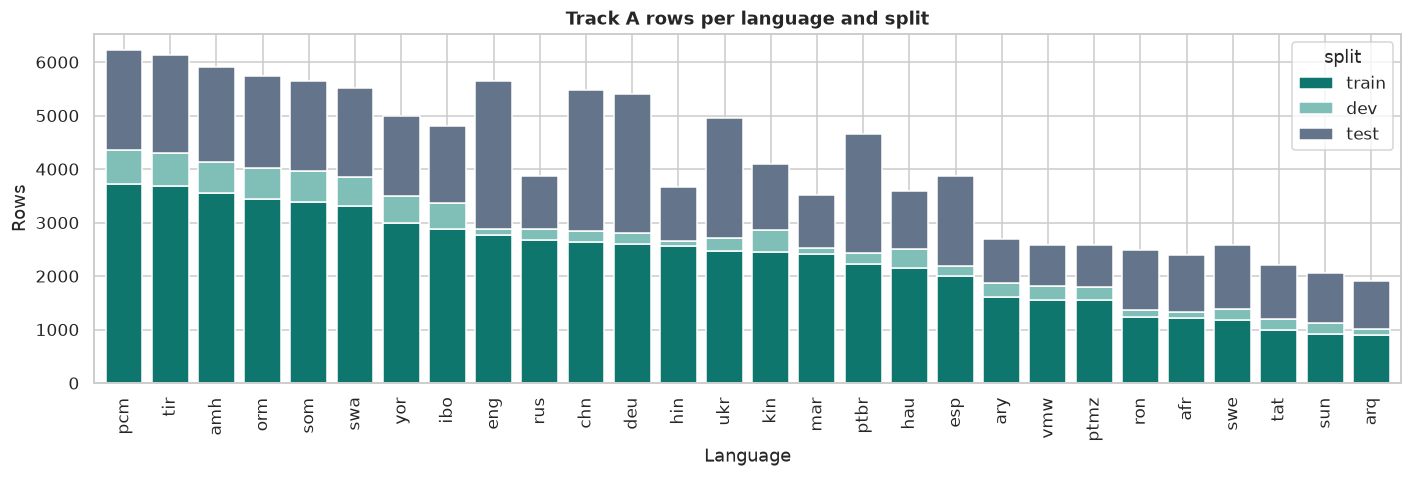

Largest training language: pcm (3,728 rows)
Smallest training language: arq (901 rows)
Ratio: 4.1


In [14]:
rows = (track_a.groupBy("lang", "split").count().toPandas()
        .pivot(index="lang", columns="split", values="count").fillna(0).astype(int))
rows = rows[["train", "dev", "test"]].sort_values("train", ascending=False)

ax = rows.plot.bar(stacked=True, figsize=(13, 4.5), color=[TEAL, "#7FBFB8", SLATE], width=0.8)
ax.set(title="Track A rows per language and split", xlabel="Language", ylabel="Rows")
plt.show()

print(f"Largest training language: {rows['train'].idxmax()} ({rows['train'].max():,} rows)")
print(f"Smallest training language: {rows['train'].idxmin()} ({rows['train'].min():,} rows)")
print(f"Ratio: {rows['train'].max() / rows['train'].min():.1f}")

**Interpretation.** Languages differ in size, so a plain random batch would favour the largest ones. Training therefore samples languages with a temperature of 0.7, which narrows that gap. Here the largest language, Nigerian Pidgin (pcm), has 3,728 training rows and the smallest, Algerian Arabic (arq), has 901, a ratio of 4.1.

### 3.4 Language families

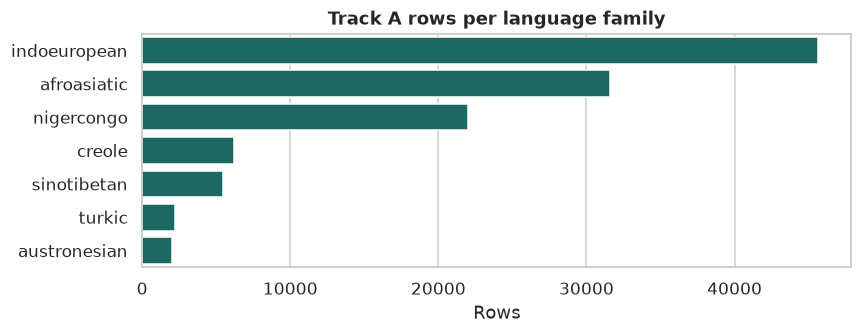

| family | languages | rows | share_of_rows |
|---|---|---|---|
| indoeuropean | 12.00 | 45,608.00 | 0.396 |
| afroasiatic | 7.00 | 31,612.00 | 0.275 |
| nigercongo | 5.00 | 21,981.00 | 0.191 |
| creole | 1.00 | 6,218.00 | 0.054 |
| sinotibetan | 1.00 | 5,484.00 | 0.048 |
| turkic | 1.00 | 2,200.00 | 0.019 |
| austronesian | 1.00 | 2,049.00 | 0.018 |

In [15]:
by_family = (track_a.join(F.broadcast(family_map), "lang")
             .groupBy("family")
             .agg(F.countDistinct("lang").alias("languages"), F.count("*").alias("rows"))
             .orderBy(F.desc("rows")).toPandas().set_index("family"))
by_family["share_of_rows"] = by_family["rows"] / by_family["rows"].sum()

fig, ax = plt.subplots(figsize=(8, 3.2))
sns.barplot(data=by_family.reset_index(), y="family", x="rows", color=TEAL, ax=ax)
ax.set(title="Track A rows per language family", xlabel="Rows", ylabel="")
plt.show()
by_family

**Interpretation.** Three families hold nearly all of the data, while Sino-Tibetan, Turkic and the creole family have one language each. A family prior can only help when a family has several languages.

### 3.5 Which emotions exist in each language

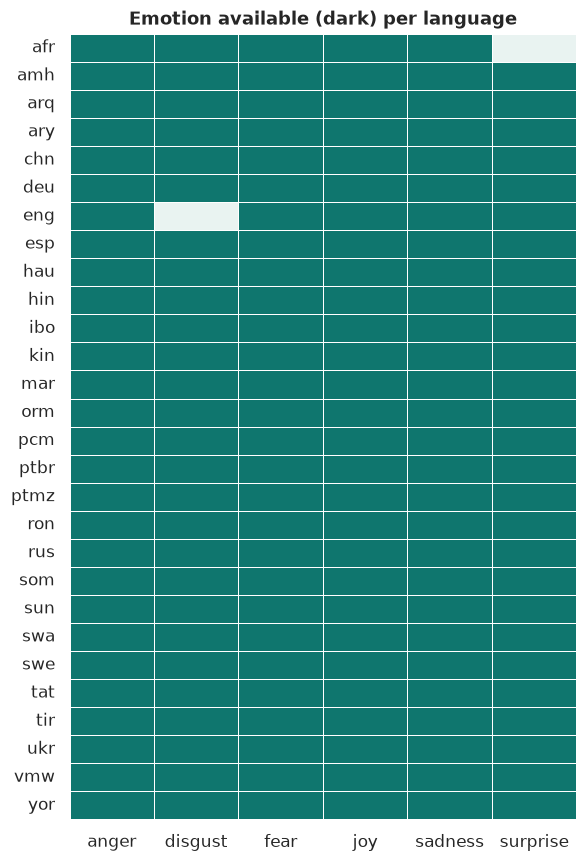

Languages missing an emotion: {'afr': ['surprise'], 'eng': ['disgust']}


In [16]:
availability = pd.DataFrame(masks, index=EMOS).T.sort_index()
availability = availability.loc[sorted(l for l in availability.index if l in rows.index)]

fig, ax = plt.subplots(figsize=(5.5, 8))
sns.heatmap(availability, cmap=sns.light_palette(TEAL, as_cmap=True), cbar=False, linewidths=0.5, ax=ax)
ax.set(title="Emotion available (dark) per language", xlabel="", ylabel="")
plt.show()

missing = {lang: [e for e in EMOS if not availability.loc[lang, e]] for lang in availability.index}
print("Languages missing an emotion:", {k: v for k, v in missing.items() if v})

**Relevance.** A missing emotion is not the same as a zero label. Absent emotions are masked in the loss, in the graphs and in the metrics.

### 3.6 Label prevalence

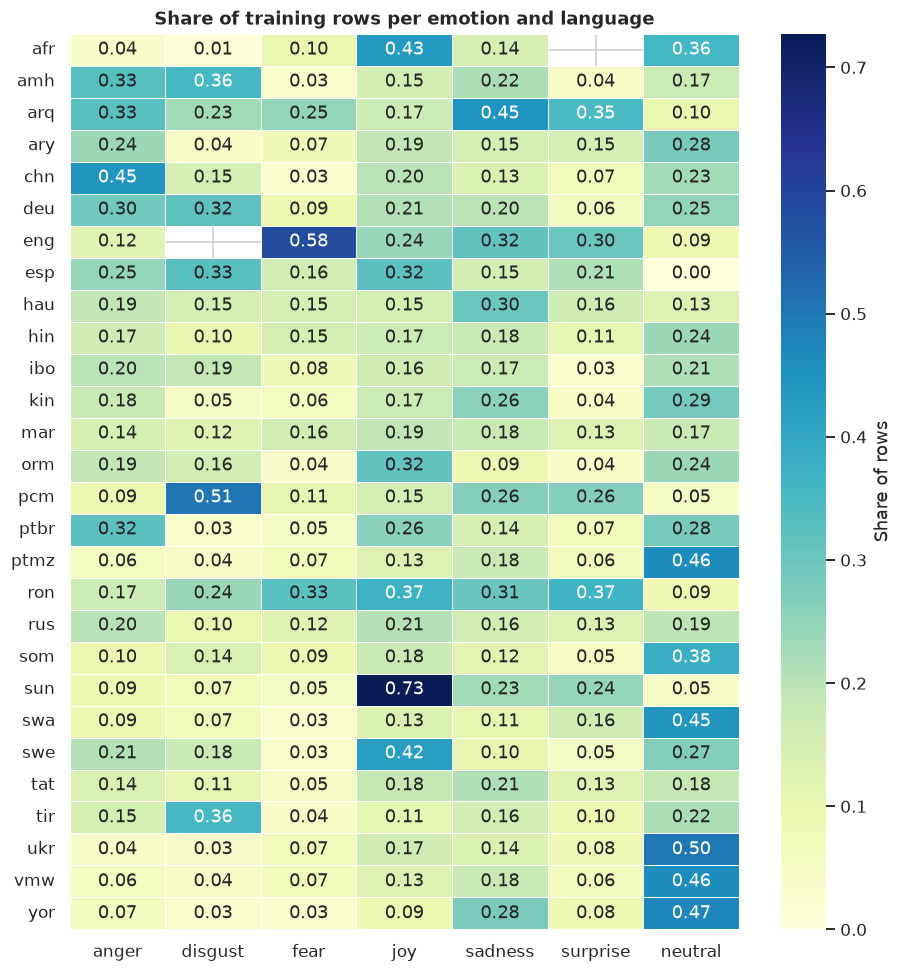

|  | min | median | max | lowest_language | highest_language |
|---|---|---|---|---|---|
| anger | 0.036 | 0.167 | 0.446 | afr | chn |
| disgust | 0.01 | 0.124 | 0.506 | afr | pcm |
| fear | 0.026 | 0.072 | 0.582 | yor | eng |
| joy | 0.091 | 0.179 | 0.727 | yor | sun |
| sadness | 0.087 | 0.177 | 0.448 | orm | arq |
| surprise | 0.026 | 0.096 | 0.368 | ibo | ron |
| neutral | 0.00 | 0.232 | 0.499 | esp | ukr |

In [17]:
prevalence = (train_a.groupBy("lang")
              .agg(*[F.avg(e).alias(e) for e in EMOS], F.avg("neutral").alias("neutral"))
              .toPandas().set_index("lang").sort_index())

fig, ax = plt.subplots(figsize=(8.5, 9))
sns.heatmap(prevalence, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.4, cbar_kws={"label": "Share of rows"}, ax=ax)
ax.set(title="Share of training rows per emotion and language", xlabel="", ylabel="")
plt.show()

spread = prevalence.agg(["min", "median", "max"]).T
spread["lowest_language"] = prevalence.idxmin()
spread["highest_language"] = prevalence.idxmax()
spread

**Interpretation.** Each emotion swings widely across languages, so one set of statistics would not fit them all. Blank cells are emotions a language does not have. The table under the heatmap gives the range. Fear runs from 2.6% of rows (Yoruba) to 58.2% (English), and joy from 9.1% (Yoruba) to 72.7% (Sundanese). The `min`, `median` and `max` columns are shares of rows, and the two language columns name where the lowest and highest values occur.

### 3.7 The English fear skew

English deserves a closer look, because its label balance differs sharply from the other languages, and most application text is English.

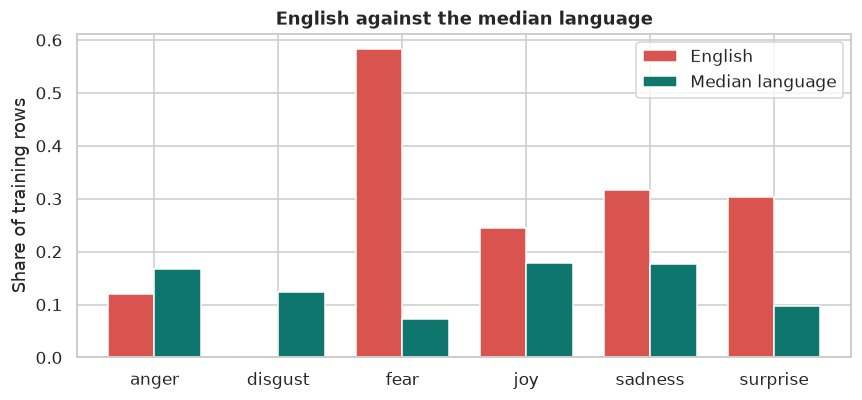

|  | P(fear | emotion), English |
|---|---|
| anger | 0.718 |
| joy | 0.154 |
| sadness | 0.777 |
| surprise | 0.697 |

In [18]:
compare = pd.DataFrame({"English": prevalence.loc["eng"], "Median language": prevalence.median()}).drop("neutral")

ax = compare.plot.bar(figsize=(8, 3.8), color=[CORAL, TEAL], rot=0, width=0.75)
ax.set(title="English against the median language", ylabel="Share of training rows", xlabel="")
plt.show()

eng = train_a.filter(F.col("lang") == "eng")
given = {e: eng.filter(F.col(e) == 1).agg(F.avg("fear")).first()[0] for e in EMOS if e not in ("fear", "disgust")}
pd.Series(given, name="P(fear | emotion), English").to_frame()

**Relevance.** Fear dominates English training rows and often accompanies other emotions. A model trained on this learns to expect fear in negative English text, which later affects the applications. The table gives the English figures: when a text is labelled anger, sadness or surprise, it is also labelled fear about 70% to 78% of the time, but only 15% of the time when it is labelled joy.

### 3.8 How many emotions does a text carry?

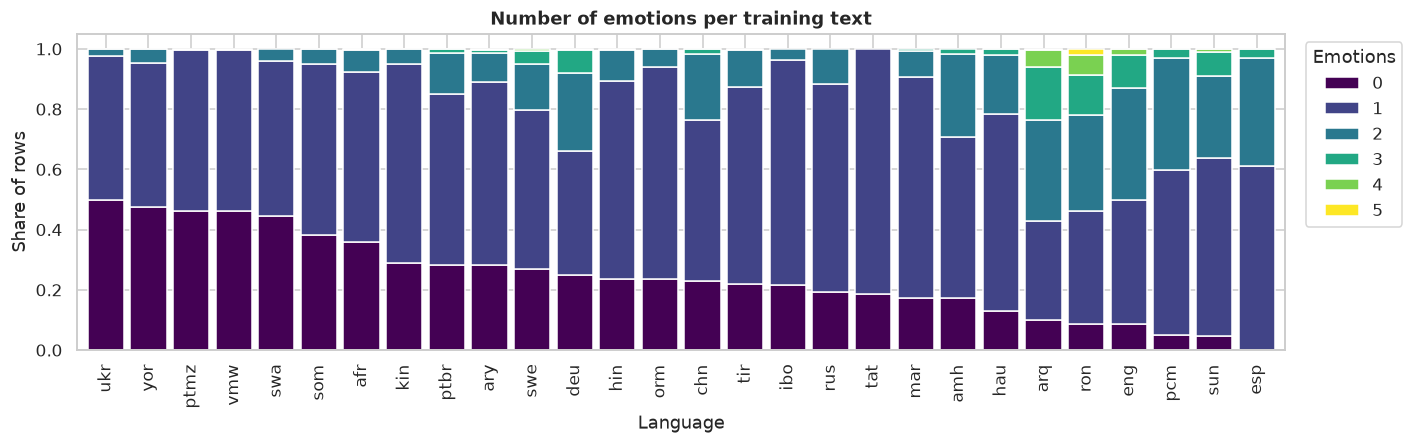

Mean emotions per text: lowest 0.53 (ukr), highest 1.78 (ron)


In [19]:
label_count = sum(F.coalesce(F.col(e), F.lit(0)) for e in EMOS)
counts = (train_a.withColumn("n_labels", label_count)
          .groupBy("lang", "n_labels").count().toPandas()
          .pivot(index="lang", columns="n_labels", values="count").fillna(0))
share = counts.div(counts.sum(axis=1), axis=0)
share = share.sort_values(0, ascending=False)

ax = share.plot.bar(stacked=True, figsize=(13, 4.2), colormap="viridis", width=0.85)
ax.set(title="Number of emotions per training text", xlabel="Language", ylabel="Share of rows")
ax.legend(title="Emotions", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

mean_labels = (counts * counts.columns.values).sum(axis=1) / counts.sum(axis=1)
print(f"Mean emotions per text: lowest {mean_labels.min():.2f} ({mean_labels.idxmin()}), "
      f"highest {mean_labels.max():.2f} ({mean_labels.idxmax()})")

**Interpretation.** Multi-label rows are common in some languages and rare in others. A model that reads label relations from data has more to work with where several emotions co-occur. Each bar is one language, and the colours show the share of its texts with 0, 1, 2 or more emotions. The mean number of emotions per text runs from 0.53 (Ukrainian) to 1.78 (Romanian).

### 3.9 How emotions relate to each other

Conditional probability shows how often emotion $j$ appears given emotion $i$. NPMI adjusts for how common each emotion is: positive values mean the pair attracts, and negative values mean it repels.

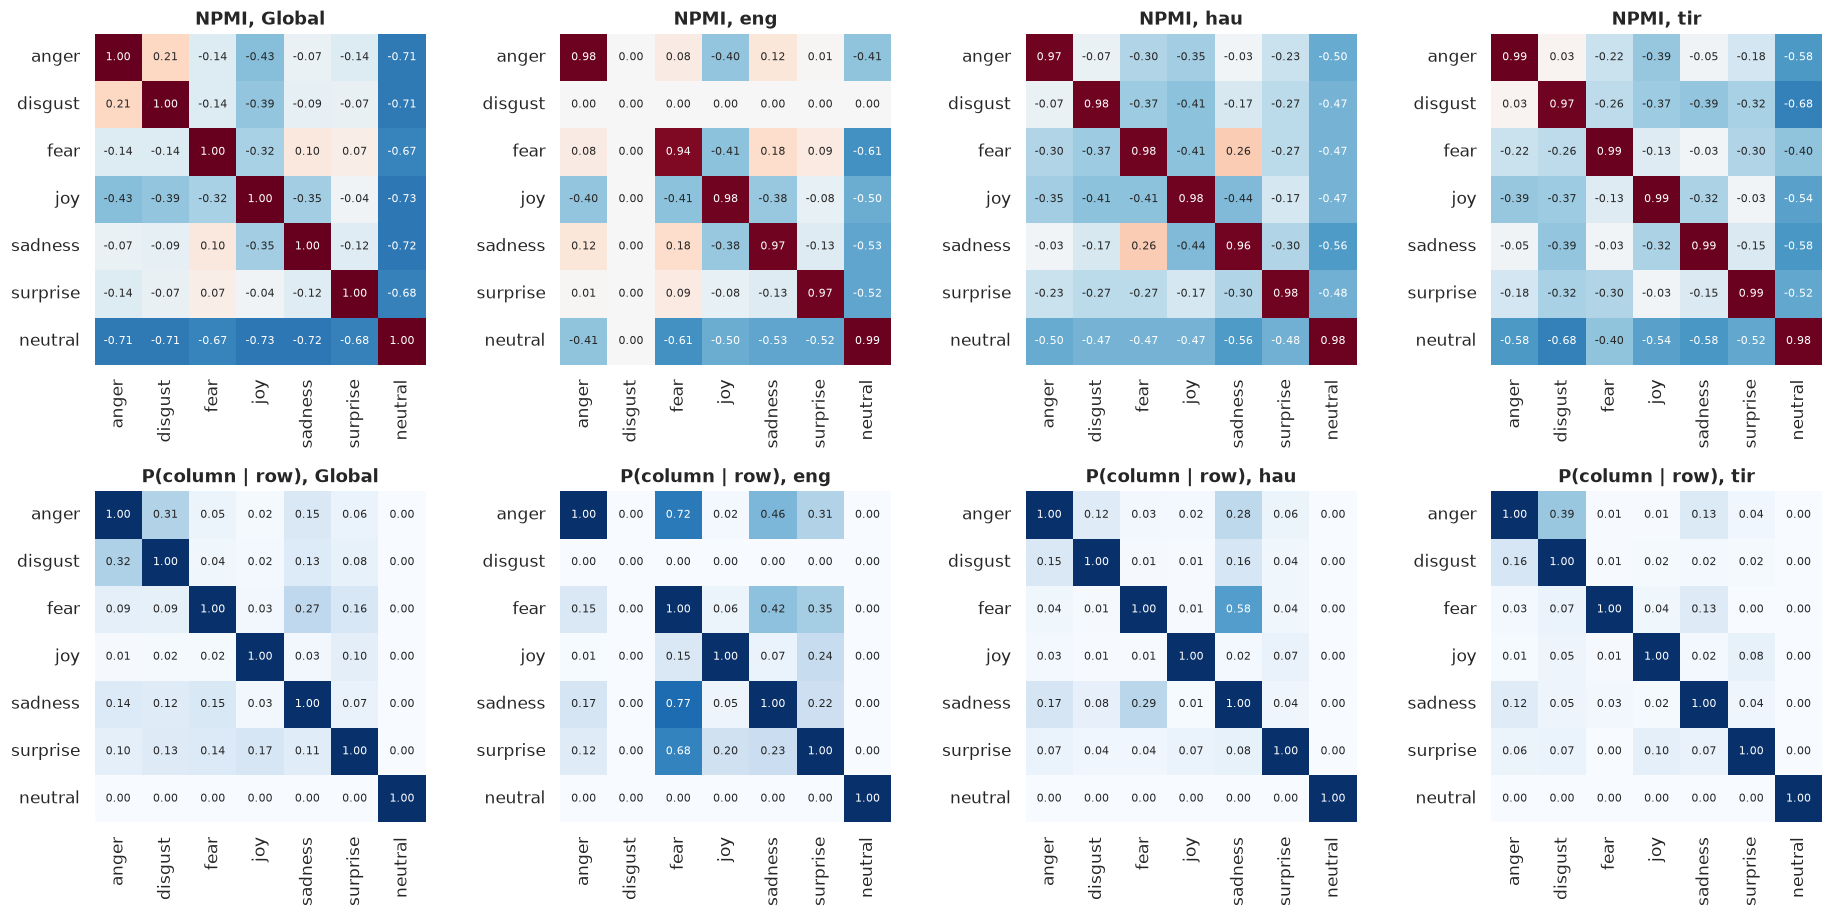

In [20]:
def graph_matrix(scope_type, scope, value):
    rows_ = (graphs.filter((F.col("scope_type") == scope_type) & (F.col("scope") == scope))
             .select("i", "j", value).toPandas())
    return rows_.pivot(index="i", columns="j", values=value).reindex(index=NODES, columns=NODES)


views = [("global", "global"), ("lang", "eng"), ("lang", "hau"), ("lang", "tir")]
scope_names = {r["scope"] for r in graphs.filter(F.col("scope_type") == "global").select("scope").distinct().collect()}
views[0] = ("global", sorted(scope_names)[0])

fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
for col, (kind, scope) in enumerate(views):
    title = "Global" if kind == "global" else scope
    sns.heatmap(graph_matrix(kind, scope, "npmi"), ax=axes[0, col], cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                annot=True, fmt=".2f", annot_kws={"size": 7}, cbar=False, square=True)
    axes[0, col].set(title=f"NPMI, {title}", xlabel="", ylabel="")
    sns.heatmap(graph_matrix(kind, scope, "p_j_given_i"), ax=axes[1, col], cmap="Blues", vmin=0, vmax=1,
                annot=True, fmt=".2f", annot_kws={"size": 7}, cbar=False, square=True)
    axes[1, col].set(title=f"P(column | row), {title}", xlabel="", ylabel="")
plt.show()

**Interpretation.** Each square is one pair of emotions, and each column is one view: the global graph, then English, Hausa and Tigrinya. In the top row, red means the pair occurs more often than chance, and blue means less often. In the bottom row, darker blue means the column emotion is more likely given the row emotion. English has a blank disgust row and column because it has no disgust label. Its bottom row shows the fear skew: fear is likely given anger, sadness or surprise.

In [21]:
pairs = (graphs.filter((F.col("scope_type") == "global") & (F.col("i") < F.col("j")))
         .select("i", "j", "npmi", "p_j_given_i").toPandas().sort_values("npmi", ascending=False))
print("Strongest attracting and repelling pairs, globally")
pd.concat([pairs.head(4), pairs[pairs["i"] != "neutral"].tail(4)]).reset_index(drop=True)

Strongest attracting and repelling pairs, globally


|  | i | j | npmi | p_j_given_i |
|---|---|---|---|---|
| 0 | anger | disgust | 0.207 | 0.315 |
| 1 | fear | sadness | 0.103 | 0.273 |
| 2 | fear | surprise | 0.068 | 0.158 |
| 3 | joy | surprise | -0.043 | 0.101 |
| 4 | fear | neutral | -0.665 | 0.00 |
| 5 | disgust | neutral | -0.713 | 0.00 |
| 6 | anger | neutral | -0.713 | 0.00 |
| 7 | joy | neutral | -0.726 | 0.00 |

**Interpretation.** Some relations hold across languages, while their strength varies. Conditional probability alone cannot show repulsion, which is the motivation for testing a signed graph. In the table, pairs at the top attract and pairs at the bottom repel. Anger and disgust attract most strongly (NPMI 0.207), while every emotion strongly repels neutral, as it should, since neutral means no emotion is present. Joy and surprise show why NPMI is useful: 10% of joy texts also carry surprise, yet the NPMI of $-0.043$ says that is slightly less often than chance.

### 3.10 Text and token length

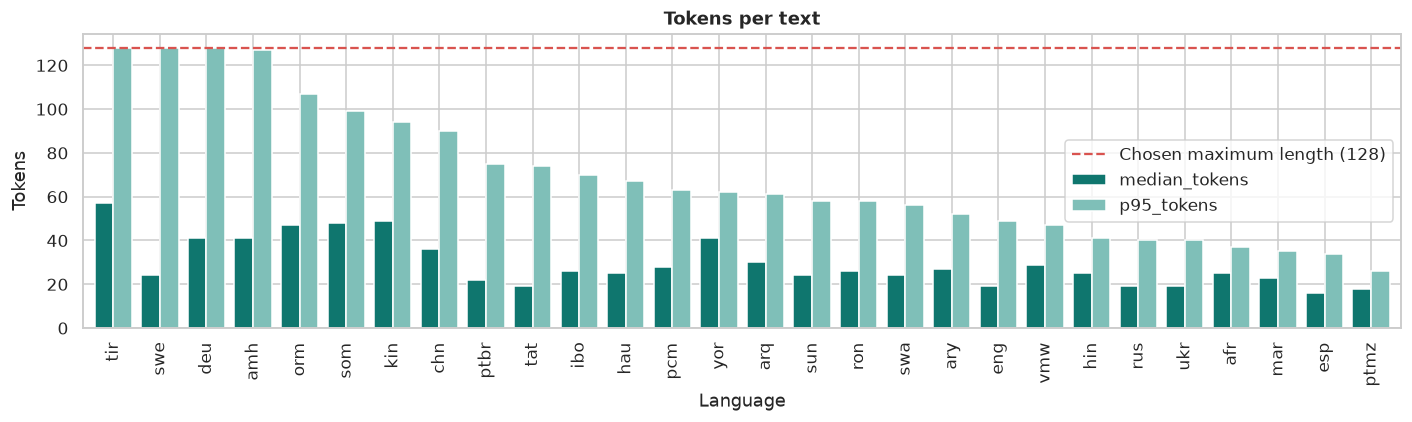

Rows at the maximum length: 1,647 of 122,345


In [22]:
lengths = (track_a.withColumn("words", F.size(F.split(F.trim("text"), r"\s+"))).withColumn("chars", F.length("text"))
           .groupBy("lang")
           .agg(F.percentile_approx("words", 0.5).alias("median_words"),
                F.percentile_approx("words", 0.95).alias("p95_words"),
                F.percentile_approx("chars", 0.5).alias("median_chars"))
           .toPandas().set_index("lang"))
tokens = (tokenized.filter(F.col("track") == "A").groupBy("lang")
          .agg(F.percentile_approx("length", 0.5).alias("median_tokens"),
               F.percentile_approx("length", 0.95).alias("p95_tokens"),
               F.max("length").alias("max_tokens"))
          .toPandas().set_index("lang"))
length_table = lengths.join(tokens).sort_values("p95_tokens", ascending=False)

max_len = json.loads(Path(path_of(cfg, "gold", "tokenizer_meta.json")).read_text())["max_len"]
ax = length_table[["median_tokens", "p95_tokens"]].plot.bar(figsize=(13, 4), color=[TEAL, "#7FBFB8"], width=0.8)
ax.axhline(max_len, color=CORAL, linestyle="--", label=f"Chosen maximum length ({max_len})")
ax.set(title="Tokens per text", xlabel="Language", ylabel="Tokens")
ax.legend()
plt.show()

print(f"Rows at the maximum length: {tokenized.filter(F.col('length') >= max_len).count():,} "
      f"of {tokenized.count():,}")

**Interpretation.** Texts are short in most languages. The maximum length covers the 95th percentile for most of them and keeps memory use within a 4 GB GPU. Languages whose bars cross the dashed line lose the end of their longest texts. Only 1,647 of the 122,345 rows (1.3%) reach the limit of 128 tokens.

### 3.11 What cleaning changed

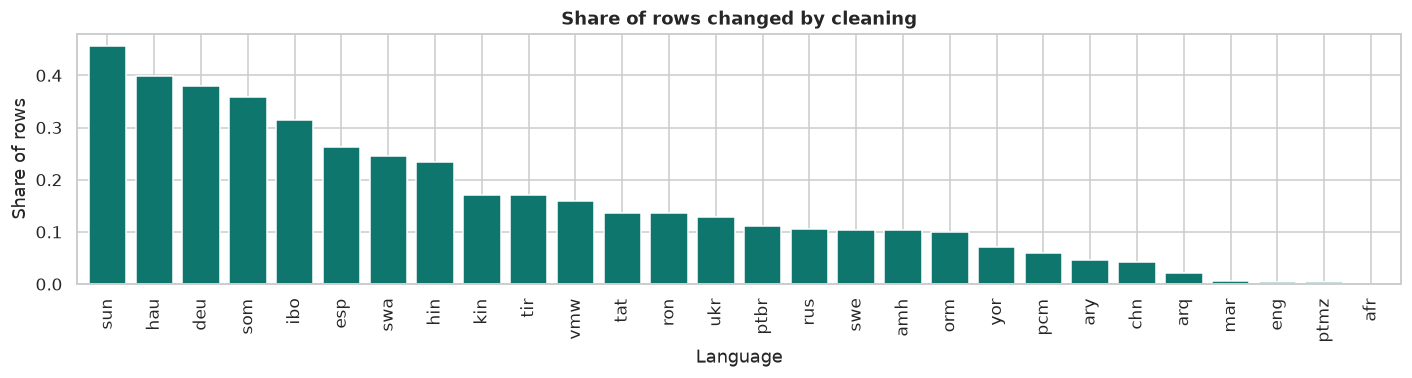

Rows changed overall: 15.8%
Rows with a masked link: 0.01%
Rows with a masked user handle: 0.00%


In [23]:
cleaned = (track_a.groupBy("lang")
           .agg(F.count("*").alias("rows"),
                F.avg((F.col("text") != F.col("text_raw")).cast("int")).alias("changed"),
                F.avg(F.col("text").contains("[URL]").cast("int")).alias("has_url"),
                F.avg(F.col("text").contains("[USER]").cast("int")).alias("has_user"))
           .toPandas().set_index("lang").sort_values("changed", ascending=False))

ax = cleaned["changed"].plot.bar(figsize=(13, 3.6), color=TEAL, width=0.8)
ax.set(title="Share of rows changed by cleaning", xlabel="Language", ylabel="Share of rows")
plt.show()

total = cleaned["rows"].sum()
print(f"Rows changed overall: {(cleaned['changed'] * cleaned['rows']).sum() / total:.1%}")
print(f"Rows with a masked link: {(cleaned['has_url'] * cleaned['rows']).sum() / total:.2%}")
print(f"Rows with a masked user handle: {(cleaned['has_user'] * cleaned['rows']).sum() / total:.2%}")

**Interpretation.** The share of rows changed by cleaning varies widely, from almost none for some languages (for example English, Marathi and Afrikaans) to over 40% for Sundanese. A separate check on the changed rows found that about half contain emoji, and that most of the rest differ only in spacing, with some emoticons and Unicode fixes. Links and user handles are rare in this dataset, so masking touches very few rows. Turning emoji into words keeps their meaning available to the encoder.

### 3.12 Intensity labels (Track B)

Intensity runs from 0 (none) to 3 (high). The value $-1$ marks an emotion with no intensity label.

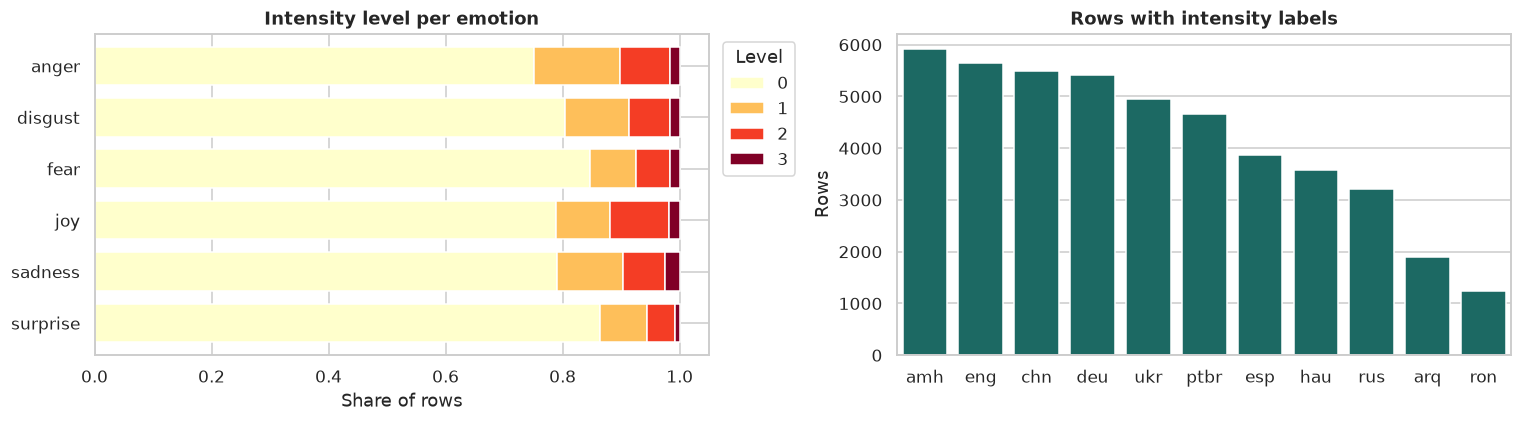

Languages with intensity labels: 11 of 28
Share of rows above zero:
emotion
anger      0.248
disgust    0.195
fear       0.154
joy        0.212
sadness    0.209
surprise   0.136


In [24]:
exploded = (intensity.select("lang", "id", F.posexplode("intensity").alias("position", "level"))
            .filter(F.col("level") >= 0))
levels = exploded.groupBy("position", "level").count().toPandas()
levels["emotion"] = levels["position"].map(dict(enumerate(EMOS)))
table = levels.pivot(index="emotion", columns="level", values="count").fillna(0).reindex(EMOS)
share = table.div(table.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
share.plot.barh(stacked=True, colormap="YlOrRd", ax=axes[0], width=0.75)
axes[0].set(title="Intensity level per emotion", xlabel="Share of rows", ylabel="")
axes[0].invert_yaxis()
axes[0].legend(title="Level", bbox_to_anchor=(1.01, 1), loc="upper left")

per_lang = exploded.groupBy("lang").agg(F.countDistinct("id").alias("rows")).toPandas().sort_values("rows", ascending=False)
sns.barplot(data=per_lang, x="lang", y="rows", color=TEAL, ax=axes[1])
axes[1].set(title="Rows with intensity labels", xlabel="", ylabel="Rows")
plt.show()

print(f"Languages with intensity labels: {len(per_lang)} of {rows.shape[0]}")
print("Share of rows above zero:")
print((1 - share[0]).round(3).to_string())

**Relevance.** Most languages have no intensity labels, so the intensity head sees only part of the data. Early work forced about half of each batch to come from these languages. The selected model drops that rule, and Part 7 shows the effect by group. In the left chart, level 0 dominates every emotion, and only 14% to 25% of rows have an intensity above zero. The right chart counts the rows with intensity labels per language.

### 3.13 Do the splits match?

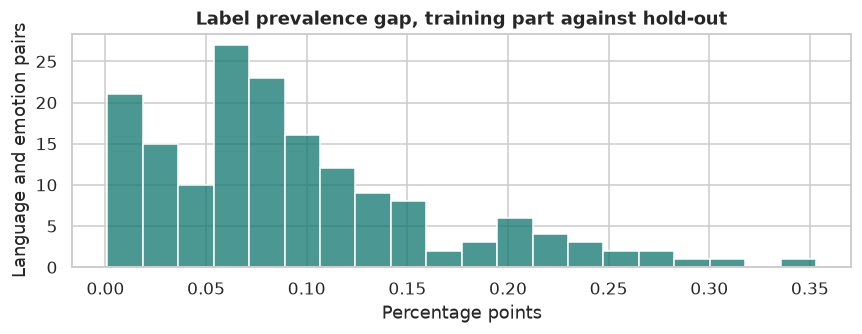

|  | track | part | count |
|---|---|---|---|
| 0 | A | test | 41553 |
| 1 | A | train | 55317 |
| 2 | A | val | 18282 |
| 3 | C | c_dev | 1864 |
| 4 | C | test | 5329 |

Largest gap: 0.35 points; pairs above 3 points: 0


In [25]:
split_check = pd.read_csv(path_of(cfg, "reports", "split_check.csv"))
holdout = split_check[split_check["view"] == "holdout"]

fig, ax = plt.subplots(figsize=(8, 3.2))
sns.histplot(holdout["abs_diff_pp"], bins=20, color=TEAL, ax=ax)
ax.set(title="Label prevalence gap, training part against hold-out", xlabel="Percentage points", ylabel="Language and emotion pairs")
plt.show()

display(parts.groupBy("track", "part").count().orderBy("track", "part").toPandas())
print(f"Largest gap: {holdout['abs_diff_pp'].max():.2f} points; pairs above 3 points: {(holdout['abs_diff_pp'] > 3).sum()}")

**Interpretation.** Small gaps confirm that stratification worked, so validation scores should reflect how each language's labels are balanced in training. The largest gap between the training part and the hold-out is 0.35 percentage points, and no pair exceeds 3 points. The table underneath gives the number of rows in each part. `c_dev` is the Track C development data, which is not used for training or validation.

### 3.14 Exact duplicates across splits

In [26]:
duplicates = (track_a.groupBy("lang", "text").agg(F.countDistinct("split").alias("splits"))
              .filter("splits > 1").groupBy("lang").count().orderBy(F.desc("count")).toPandas())
print(f"Distinct texts found in more than one split: {duplicates['count'].sum():,}")
duplicates.set_index("lang").T if len(duplicates) else "None"

Distinct texts found in more than one split: 123


|  | ibo | swa | orm | tir | eng | swe | hin | som | esp | ptbr |
|---|---|---|---|---|---|---|---|---|---|---|
| count | 96 | 10 | 7 | 4 | 1 | 1 | 1 | 1 | 1 | 1 |

**Decision.** A small number of texts repeat across splits. The official splits are kept as released, so scores stay comparable with the task, and this is noted as a limitation. There are 123 such texts, and 96 of them are in Igbo.

### 3.15 EDA summary

The next cell collects the main figures from this section.

In [27]:
fear_eng, fear_med = prevalence.loc["eng", "fear"], prevalence["fear"].median()
display(Markdown(f'''
- **Scale:** {rows.values.sum():,} Track A rows in {rows.shape[0]} languages and {len(set(FAMILY.values()))} families.
- **Uneven size:** the largest language has {rows['train'].max() / rows['train'].min():.1f} times the training rows of the smallest.
- **Label skew:** fear is {fear_eng:.1%} of English training rows, against a median of {fear_med:.1%}.
- **Text length:** the longest language has a 95th percentile of {length_table['p95_tokens'].max():.0f} tokens, and the maximum length is {max_len}.
- **Intensity:** only {len(per_lang)} of {rows.shape[0]} languages have intensity labels.

These findings shaped the model: sample languages with a temperature, mask absent emotions, use per-language graphs, and handle partial intensity labels.
'''))


- **Scale:** 115,152 Track A rows in 28 languages and 7 families.
- **Uneven size:** the largest language has 4.1 times the training rows of the smallest.
- **Label skew:** fear is 58.2% of English training rows, against a median of 7.2%.
- **Text length:** the longest language has a 95th percentile of 128 tokens, and the maximum length is 128.
- **Intensity:** only 11 of 28 languages have intensity labels.

These findings shaped the model: sample languages with a temperature, mask absent emotions, use per-language graphs, and handle partial intensity labels.


Spark is stopped here, which frees memory for GPU training.

In [28]:
spark.stop()

## 4. Baseline B1: TF-IDF in Spark MLlib

B1 uses hashed term frequencies with IDF, and one logistic regression per emotion. Thresholds are tuned on validation. It gives a simple reference point for the neural models.

In [29]:
b1_path = Path(path_of(cfg, "reports", "results_b1.csv"))
if RUN_BASELINE:
    run_job("08_baseline_tfidf")
    show_job("08_baseline_tfidf")

if b1_path.exists():
    b1 = pd.read_csv(b1_path)
    print("Baseline results (results_b1.csv), first rows:")
    display(b1.head(6))
    b1 = b1[b1["part"] == "test"].set_index("lang")["macro_f1"] * 100
    print(f"B1 test macro-F1, mean over {len(b1)} languages: {b1.mean():.2f}")
else:
    b1 = pd.Series(dtype=float)
    print("Baseline not run.")

08_baseline_tfidf: exists, skipping: /home/chanakya/emoldgn_starter/data/notebook/reports/results_b1.csv

From the job log, the run that built these tables (last 8 of 8 lines):
08_baseline_tfidf: trained anger
08_baseline_tfidf: trained disgust
08_baseline_tfidf: trained fear
08_baseline_tfidf: trained joy
08_baseline_tfidf: trained sadness
08_baseline_tfidf: trained surprise
08_baseline_tfidf: B1 val mean macro-F1: 0.4214
08_baseline_tfidf: B1 test mean macro-F1: 0.3976


Baseline results (results_b1.csv), first rows:


|  | part | lang | macro_f1 |
|---|---|---|---|
| 0 | val | afr | 0.286 |
| 1 | val | amh | 0.499 |
| 2 | val | arq | 0.498 |
| 3 | val | ary | 0.324 |
| 4 | val | chn | 0.267 |
| 5 | val | deu | 0.463 |

B1 test macro-F1, mean over 28 languages: 39.76


**Interpretation.** One logistic regression is trained per emotion. The table lists scores per language as fractions, so 0.286 means a macro-F1 of 28.6. The baseline reaches **42.14 on validation and 39.76 on test**, which is the score the neural models need to beat. Section 7 compares them.

## 5. Models

Both models share one implementation, `EmoLDGNPlus` in `emoldgn/model.py`, and switch components on with flags.

**Shared base (LDGN on XLM-RoBERTa):**

1. The encoder produces a state for each token.
2. Each emotion attends over those states, giving one representation of the text per emotion.
3. A first GCN shares information over the language's co-occurrence graph.
4. A dynamic graph is built for this specific text.
5. A second GCN shares information over that graph.
6. The two GCN outputs are combined, and each emotion gets a probability.

**What the selected model adds (N6):** an ordinal intensity head that predicts intensity 0 to 3 from the same representations. Its loss combines ordinal, distance-aware and Pearson terms. Rows without intensity labels are skipped, and no quota is applied to batches.

In [30]:
from emoldgn import evaluate as E
from emoldgn.predict import predict_run
from emoldgn.train import resolve, run_with_retries

settings = []
for exp in ("b4_full", "best_full"):
    c = resolve(exp)
    on = [k for k, v in c["exp"]["flags"].items() if v is True]
    settings.append({"run": exp, "additions": ", ".join(on) or "none", "intensity quota": c["exp"].get("intensity_quota", True) and "n6_intensity" in on,
                     "batch size": c["batch_size"], "grad accumulation": c["grad_accum"], "encoder lr": c["lr_encoder"],
                     "head lr": c["lr_head"], "max length": c["max_len"], "frozen word embeddings": c["freeze_word_embeddings"]})
pd.DataFrame(settings).set_index("run").T

|  | b4_full | best_full |
|---|---|---|
| additions | none | n6_intensity |
| intensity quota | False | False |
| batch size | 16 | 16 |
| grad accumulation | 2 | 2 |
| encoder lr | 0.00 | 0.00 |
| head lr | 0.001 | 0.001 |
| max length | 128 | 128 |
| frozen word embeddings | True | True |

**Interpretation.** The two models differ only in the first row: the selected model adds the intensity head (`n6_intensity`), and all other settings are the same, so differences between them come from that addition. Neither model uses the intensity quota. The encoder learning rate shows as 0.00 only because the table rounds to three decimals; the actual value is 0.00002.

## 6. Training and testing

For each model, the function below first looks for trained weights, then does the following:

| Situation | What happens |
|---|---|
| This notebook already finished the run | Loads its results |
| Weights from the original run exist (`runs/<name>/ckpt_best.pt`) and `FORCE_RETRAIN` is `False` | **Reuses those weights**: links them into a new folder, tunes thresholds on validation again, and scores test and Track C |
| Otherwise | **Trains from scratch** with the code in `emoldgn/train.py`, saving a checkpoint after every epoch so an interrupted run can resume, then tunes thresholds and scores test |

Every cell prints which of these it used, and the results table in Part 7 repeats it, so the source of each number is never hidden.

Early stopping uses validation macro-F1. A training run allows 5 epochs, and extends to 8 while the best epoch is the last one. Only per-epoch lines are shown; the complete log is in the run folder as `train.log`.

Everything is written to `runs/nb_b4_full` and `runs/nb_best_full`. The original run folders are only read. Training is not perfectly repeatable on a GPU, so a retrained model may differ slightly from the original.

**Test split.** Thresholds and epochs come from validation only. Re-scoring a saved model with the same settings tunes nothing on test.

In [31]:
class EpochLines:
    # Shows per-epoch lines from the training log and hides the per-step lines.
    def __init__(self, stream):
        self.stream = stream

    def write(self, text):
        if " epoch " in text or "extend" in text.lower():
            self.stream.write(text)
        return len(text)

    def flush(self):
        self.stream.flush()


def finished(run_id):
    state = Path(path_of(cfg, "runs", run_id, "status.json"))
    has_test = Path(path_of(cfg, "runs", run_id, "predictions", "test.npz")).exists()
    return state.exists() and json.loads(state.read_text()).get("status") == "done" and has_test


SOURCE = {}


def link_saved_run(exp, run_id):
    original = Path(path_of(cfg, "runs", exp))
    run = Path(path_of(cfg, "runs", run_id))
    run.mkdir(parents=True, exist_ok=True)
    checkpoint = run / "ckpt_best.pt"
    if not checkpoint.exists():
        checkpoint.symlink_to((original / "ckpt_best.pt").resolve())
    for name in ("metrics.jsonl", "train.log"):  # config.yaml stays out, so scoring uses this notebook's own tables
        if (original / name).exists():
            shutil.copy(original / name, run / name)
    status = json.loads((original / "status.json").read_text()) if (original / "status.json").exists() else {}
    (run / "status.json").write_text(json.dumps({**status, "status": "done", "source": f"weights of {exp}"}))


def show_run(run_id):
    run = Path(path_of(cfg, "runs", run_id))
    log = run / "train.log"
    if log.exists():
        lines = [re.sub(r"^\S+ \S+ ", "", l)[:150] for l in log.read_text(encoding="utf-8", errors="ignore").splitlines()
                 if " epoch " in l or "extend" in l.lower()]
        print("Per-epoch training log (from train.log):")
        print("\n".join(lines))
    thresholds = json.loads((run / "thresholds.json").read_text())
    print("\nTuned global thresholds:", dict(zip(EMOS, np.round(thresholds["global"], 2).tolist())))
    rows_scored = {s: len(np.load(run / "predictions" / f"{s}.npz", allow_pickle=True)["id"]) for s in ("val", "test")}
    print("Rows scored:", rows_scored, "| source:", SOURCE.get(run_id.replace("nb_", ""), "unknown"))


def train_and_test(exp):
    run_id = f"nb_{exp}"
    saved = Path(path_of(cfg, "runs", exp, "ckpt_best.pt"))
    if finished(run_id):
        origin = json.loads(Path(path_of(cfg, "runs", run_id, "status.json")).read_text()).get("source")
        SOURCE[exp] = (f"saved {origin}, re-scored in an earlier pass of this notebook" if origin
                       else "trained from scratch in an earlier pass of this notebook")
        print(f"{exp}: already finished by this notebook ({SOURCE[exp]}); loading its results.")
        return run_id

    if saved.exists() and not FORCE_RETRAIN:
        SOURCE[exp] = f"saved weights of run {exp}, re-scored here"
        print(f"{exp}: trained weights found, re-scoring them (no training).")
        link_saved_run(exp, run_id)
        print(predict_run(exp, run_id=run_id))
        return run_id

    SOURCE[exp] = "trained from scratch in this notebook"
    print(f"{exp}: training from scratch.")
    run = Path(path_of(cfg, "runs", run_id))
    for stale in ("status.json",):
        if (run / stale).exists() and not (run / "ckpt_last.pt").exists():
            (run / stale).unlink()
    run_cfg = resolve(exp)
    resume = (run / "ckpt_last.pt").exists()
    with contextlib.redirect_stdout(EpochLines(sys.stdout)):
        status = run_with_retries(run_cfg, run, resume, MAX_STEPS)
    if status != "done":
        raise RuntimeError(f"{run_id} ended with status {status!r}; executing this cell again resumes training from the last saved epoch.")
    print(predict_run(exp, run_id=run_id))
    gc.collect()
    torch.cuda.empty_cache()
    return run_id

### 6.1 Train and test B4

LDGN with no additions. Training takes approximately 50 minutes on a 4 GB GPU.

In [32]:
run_b4 = train_and_test("b4_full")
show_run(run_b4)

b4_full: already finished by this notebook (saved weights of b4_full, re-scored in an earlier pass of this notebook); loading its results.
Per-epoch training log (from train.log):
epoch 1 val_macro_f1 0.4147 val_pearson None time 321s
epoch 2 val_macro_f1 0.4460 val_pearson None time 345s
epoch 3 val_macro_f1 0.4809 val_pearson None time 353s
epoch 4 val_macro_f1 0.4929 val_pearson None time 357s
best epoch is the last one; extending to 8 epochs
epoch 5 val_macro_f1 0.5087 val_pearson None time 357s
epoch 6 val_macro_f1 0.5086 val_pearson None time 357s
epoch 7 val_macro_f1 0.5130 val_pearson None time 362s
epoch 8 val_macro_f1 0.5217 val_pearson None time 7421s

Tuned global thresholds: {'anger': 0.7, 'disgust': 0.68, 'fear': 0.81, 'joy': 0.78, 'sadness': 0.73, 'surprise': 0.64}
Rows scored: {'val': 18282, 'test': 41553} | source: saved weights of b4_full, re-scored in an earlier pass of this notebook


**Interpretation.** Each line is one training epoch. `val_macro_f1` is measured during training with a fixed threshold of 0.5, and it rises from 0.41 to 0.52. Because the best epoch was the last of the first five, training extended to 8 epochs. `val_pearson` is `None` because B4 has no intensity head.

The 7,421 seconds shown for epoch 8 include an interruption of about two hours, during which the computer was suspended. A normal epoch takes about 6 minutes.

The tuned thresholds are the probabilities at which each emotion is switched on, chosen on validation. They are mostly well above 0.5, likely because the loss gives extra weight to positive labels, which pushes probabilities up.

### 6.2 Train and test the selected model

B4 plus the ordinal intensity head, without the quota. Training takes approximately 50 minutes.

In [33]:
run_best = train_and_test("best_full")
show_run(run_best)

best_full: already finished by this notebook (saved weights of best_full, re-scored in an earlier pass of this notebook); loading its results.
Per-epoch training log (from train.log):
epoch 1 val_macro_f1 0.4166 val_pearson 0.48948120033542764 time 358s
epoch 2 val_macro_f1 0.4589 val_pearson 0.5551281809736343 time 359s
epoch 3 val_macro_f1 0.4867 val_pearson 0.6011453530472991 time 358s
epoch 4 val_macro_f1 0.5095 val_pearson 0.6083092327427693 time 357s
best epoch is the last one; extending to 8 epochs
epoch 5 val_macro_f1 0.5212 val_pearson 0.6126589546033984 time 358s
epoch 6 val_macro_f1 0.5225 val_pearson 0.6174507139778943 time 360s
epoch 7 val_macro_f1 0.5258 val_pearson 0.6149865312820758 time 359s
epoch 8 val_macro_f1 0.5316 val_pearson 0.6175148658861986 time 356s

Tuned global thresholds: {'anger': 0.68, 'disgust': 0.7, 'fear': 0.84, 'joy': 0.79, 'sadness': 0.78, 'surprise': 0.79}
Rows scored: {'val': 18282, 'test': 41553} | source: saved weights of best_full, re-scored in

**Interpretation.** The selected model follows the same pattern, reaching a higher validation macro-F1 by the final epoch (0.5316 against 0.5217 for B4).

`val_pearson` is measured on continuous intensity values, which is why it reaches about 0.62. The official Track B score in section 7.4 uses rounded levels from 0 to 3 and is lower, at 0.574 on test.

### 6.3 Both models side by side

Macro-F1 is the official Track A metric. Two accuracy figures are added for readability:

- **Exact-match accuracy:** the share of texts where every emotion the language has is predicted correctly. This is strict, since one wrong emotion makes the whole text wrong.
- **Label accuracy:** the share of individual (text, emotion) decisions that are correct. Absent emotions, such as disgust in English, are left out of both.

Accuracy is shown for reference only. Most emotions are absent from most texts, so a model that predicts "no emotion" everywhere would already score high on label accuracy. Macro-F1 does not reward that.

In [34]:
def accuracy(run_id):
    d = E.load_preds(cfg, run_id, "test")
    keep = d["mask"] > 0
    right = (d["pred"] == d["y"]) | ~keep
    return right.all(1).mean() * 100, (d["pred"] == d["y"])[keep].mean() * 100


def summary(run_id, name):
    val = E.score_track_a(E.load_preds(cfg, run_id, "val"))["mean"] * 100
    test = E.load_preds(cfg, run_id, "test")
    exact, label = accuracy(run_id)
    pearson = E.track_b(test["intensity"], test["int_pred"], test["lang"])["mean"] if "int_pred" in test else np.nan
    c = E.load_preds(cfg, run_id, "trackc")
    return {"Model": name,
            "Macro-F1, validation": round(val, 2),
            "Macro-F1, test": round(E.score_track_a(test)["mean"] * 100, 2),
            "Exact-match accuracy, test (%)": round(exact, 2),
            "Label accuracy, test (%)": round(label, 2),
            "Track B Pearson": "n/a" if np.isnan(pearson) else round(pearson, 3),
            "Track C macro-F1": "n/a" if c is None else round(E.score_track_a(c)["mean"] * 100, 2)}


comparison = pd.DataFrame([summary(run_b4, "B4 (LDGN, no additions)"),
                           summary(run_best, "Selected (B4 + N6, no quota)")]).set_index("Model")
comparison

| Model | Macro-F1, validation | Macro-F1, test | Exact-match accuracy, test (%) | Label accuracy, test (%) | Track B Pearson | Track C macro-F1 |
|---|---|---|---|---|---|---|
| B4 (LDGN, no additions) | 54.91 | 52.54 | 41.23 | 84.48 | n/a | n/a |
| Selected (B4 + N6, no quota) | 55.89 | 53.47 | 42.67 | 85.02 | 0.574 | 20.90 |

**Interpretation.** The selected model is ahead on every shared measure:

- **Macro-F1:** +0.98 on validation and +0.93 on test.
- **Exact-match accuracy:** 42.67% against 41.23%. Only about four in ten texts have every emotion right, which shows how strict this measure is for a multi-label task across 28 languages.
- **Label accuracy:** 85.02% against 84.48%. This looks high mainly because most emotions are absent from most texts.

B4 shows `n/a` for Track B because it has no intensity head, and for Track C because this notebook only scores Track C for the selected model.

### 6.4 Training curves

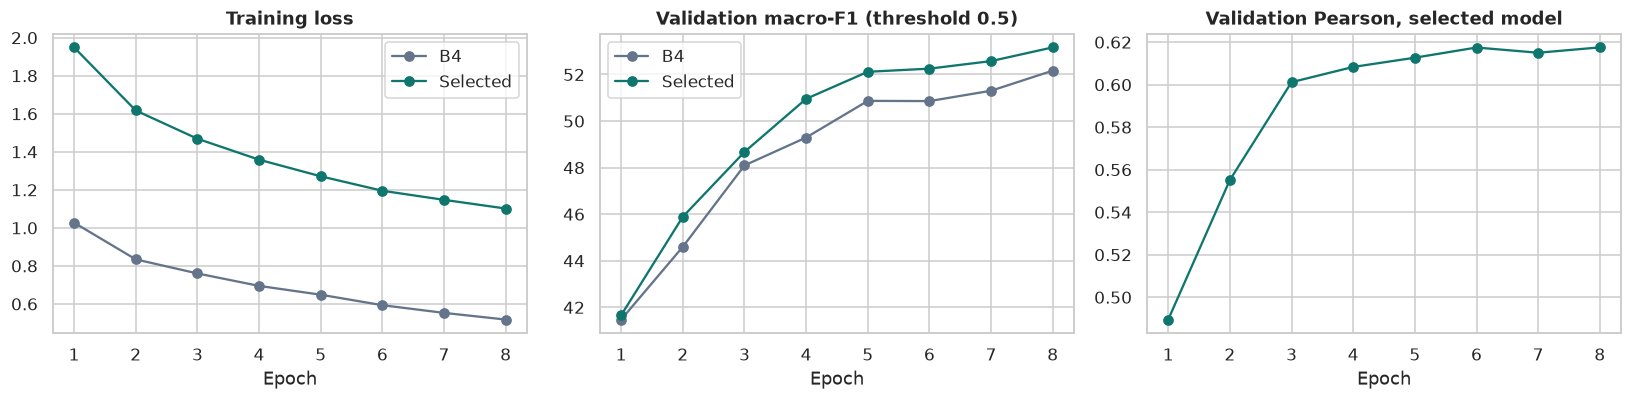

|  | B4 | Selected |
|---|---|---|
| epochs | 8.00 | 8.00 |
| best epoch | 8.00 | 8.00 |
| best validation macro-F1 | 52.17 | 53.16 |
| minutes | 164.60 | 47.80 |

In [35]:
def metrics(run_id):
    return pd.read_json(path_of(cfg, "runs", run_id, "metrics.jsonl"), lines=True).set_index("epoch")


curves = {"B4": metrics(run_b4), "Selected": metrics(run_best)}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for (name, frame), colour in zip(curves.items(), [SLATE, TEAL]):
    axes[0].plot(frame.index, frame["train_loss"], marker="o", color=colour, label=name)
    axes[1].plot(frame.index, frame["val_macro_f1"] * 100, marker="o", color=colour, label=name)
frame = curves["Selected"]
axes[2].plot(frame.index, frame["val_pearson"], marker="o", color=TEAL)
axes[0].set(title="Training loss", xlabel="Epoch")
axes[1].set(title="Validation macro-F1 (threshold 0.5)", xlabel="Epoch")
axes[2].set(title="Validation Pearson, selected model", xlabel="Epoch")
axes[0].legend(); axes[1].legend()
plt.show()

pd.DataFrame({name: {"epochs": len(f), "best epoch": int(f["val_macro_f1"].idxmax()),
                     "best validation macro-F1": round(f["val_macro_f1"].max() * 100, 2),
                     "minutes": round(f["time_s"].sum() / 60, 1)} for name, f in curves.items()})

The training loss of the selected model includes the intensity terms, so its values are not directly comparable with B4's. Validation macro-F1 is the fair comparison.

**Interpretation of the charts.** Both models improve steadily, and the best epoch for both is the last one allowed, so more epochs might still help. The selected model stays ahead of B4 from epoch 2 onwards. Its intensity correlation levels off at about 0.62 from epoch 6.

**Interpretation of the table.** The best validation macro-F1 here uses a fixed threshold of 0.5, which is why it is lower than the tuned values in section 7 (54.91 and 55.89). The 164.6 minutes for B4 include an interruption of about two hours during epoch 8, when the computer was suspended. The actual training time of B4 is approximately 47 minutes, similar to the 47.8 minutes of the selected model.

## 7. Results

Scores are in percentage points unless stated. Track A and Track C use macro-F1 per language, averaged over languages. Track B uses Pearson correlation per emotion per language, averaged.

In [36]:
display(Markdown("**Where each model's numbers come from**"))
display(pd.Series({"B4": SOURCE["b4_full"], "Selected": SOURCE["best_full"]}, name="source").to_frame())

**Where each model's numbers come from**

|  | source |
|---|---|
| B4 | saved weights of b4_full, re-scored in an earlier pass of this notebook |
| Selected | saved weights of best_full, re-scored in an earlier pass of this notebook |

**Interpretation.** This records how each model's numbers were produced in this run, so that re-scored weights are never mistaken for a fresh training run.

In [37]:
def load(run_id, split):
    data = E.load_preds(cfg, run_id, split)
    if data is None:
        raise FileNotFoundError(f"{run_id}: no {split} predictions")
    order = np.argsort(data["id"], kind="stable")
    return {k: v[order] for k, v in data.items()}


test = {"B4": load(run_b4, "test"), "Selected": load(run_best, "test")}
assert np.array_equal(test["B4"]["id"], test["Selected"]["id"]), "Models were scored on different rows."
val = {"B4": load(run_b4, "val"), "Selected": load(run_best, "val")}

scores = {k: E.score_track_a(v) for k, v in test.items()}
val_scores = {k: E.score_track_a(v) for k, v in val.items()}
per_language = pd.DataFrame({k: pd.Series(v["per_language"]) * 100 for k, v in scores.items()})
if len(b1):
    per_language.insert(0, "B1", b1)

best_data = test["Selected"]
with_intensity = sorted(l for l in per_language.index if (best_data["intensity"][best_data["lang"] == l] >= 0).any())
without_intensity = sorted(set(per_language.index) - set(with_intensity))

table = pd.DataFrame({
    "Validation (tuned)": {k: v["mean"] * 100 for k, v in val_scores.items()},
    "Test, all languages": per_language.mean(),
    f"Test, {len(with_intensity)} with intensity labels": per_language.loc[with_intensity].mean(),
    f"Test, {len(without_intensity)} without": per_language.loc[without_intensity].mean(),
}).reindex([c for c in ("B1", "B4", "Selected") if c in per_language.columns])
table.round(2)

|  | Validation (tuned) | Test, all languages | Test, 11 with intensity labels | Test, 17 without |
|---|---|---|---|---|
| B1 |  | 39.76 | 43.93 | 37.06 |
| B4 | 54.91 | 52.54 | 62.03 | 46.41 |
| Selected | 55.89 | 53.47 | 63.04 | 47.28 |

**Interpretation.** Both neural models are far ahead of the TF-IDF baseline (39.76). The selected model leads B4 by about one point overall (53.47 against 52.54).

The two right-hand columns split the languages by whether they have intensity labels. The selected model improves on B4 in both groups, by 1.01 points with intensity labels and 0.87 without, so adding the intensity head did not harm the languages that lack those labels. Languages with intensity labels score higher overall, at about 63 against 47, but those groups also differ in the languages they contain.

### 7.1 Track A by language

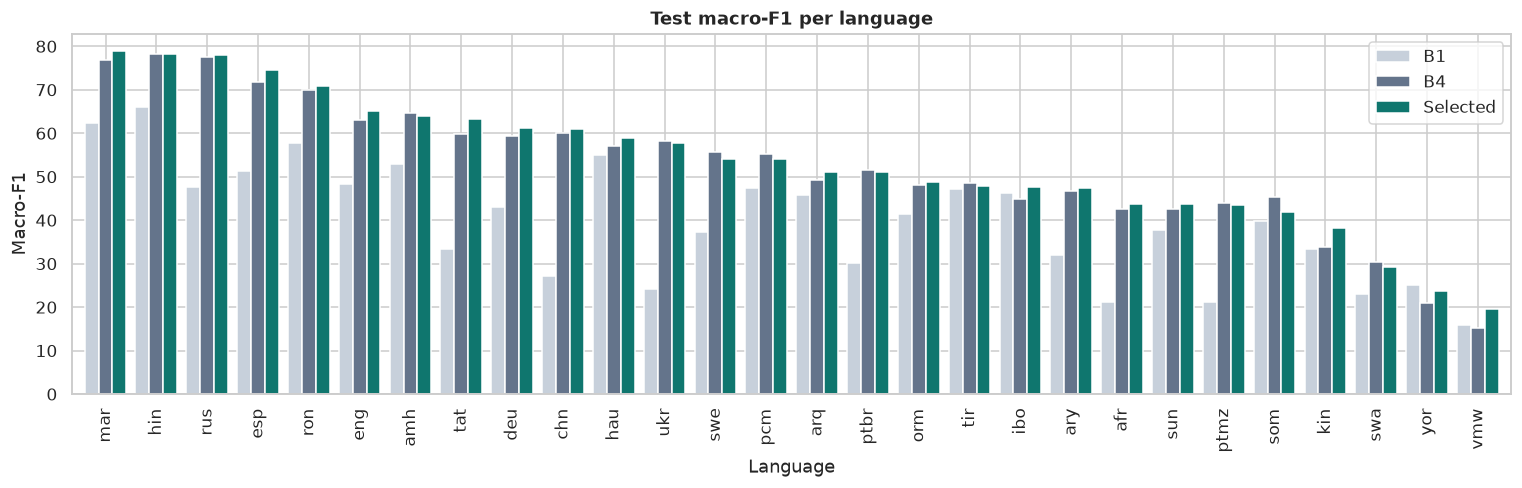

Selected beats B4 on 18 of 28 languages.
Largest gains:  {'vmw': 4.38, 'kin': 4.37, 'tat': 3.4}
Largest losses: {'som': -3.52, 'swe': -1.61, 'swa': -1.13}


|  | B1 | B4 | Selected |
|---|---|---|---|
| mar | 62.43 | 76.74 | 78.93 |
| hin | 65.93 | 78.33 | 78.22 |
| rus | 47.56 | 77.46 | 78.05 |
| esp | 51.28 | 71.86 | 74.49 |
| ron | 57.82 | 69.92 | 70.87 |
| eng | 48.40 | 62.92 | 65.01 |
| amh | 52.94 | 64.57 | 63.93 |
| tat | 33.30 | 59.89 | 63.30 |
| deu | 43.02 | 59.35 | 61.28 |
| chn | 27.15 | 60.12 | 60.88 |
| hau | 55.05 | 57.16 | 58.98 |
| ukr | 24.26 | 58.30 | 57.82 |
| swe | 37.33 | 55.77 | 54.16 |
| pcm | 47.38 | 55.18 | 54.14 |
| arq | 45.67 | 49.28 | 51.11 |
| ptbr | 30.10 | 51.42 | 51.00 |
| orm | 41.45 | 48.10 | 48.80 |
| tir | 47.25 | 48.61 | 47.81 |
| ibo | 46.15 | 44.81 | 47.57 |
| ary | 31.92 | 46.81 | 47.41 |
| afr | 21.13 | 42.63 | 43.81 |
| sun | 37.65 | 42.46 | 43.63 |
| ptmz | 21.06 | 43.87 | 43.47 |
| som | 39.81 | 45.29 | 41.78 |
| kin | 33.29 | 33.89 | 38.26 |
| swa | 23.01 | 30.43 | 29.30 |
| yor | 24.97 | 20.91 | 23.60 |
| vmw | 15.99 | 15.16 | 19.54 |

In [38]:
ordered = per_language.sort_values("Selected", ascending=False)
ax = ordered.plot.bar(figsize=(14, 4.6), width=0.82, color={"B1": "#C7D0DB", "B4": SLATE, "Selected": TEAL})
ax.set(title="Test macro-F1 per language", xlabel="Language", ylabel="Macro-F1")
plt.show()

gap = per_language["Selected"] - per_language["B4"]
print(f"Selected beats B4 on {(gap > 0).sum()} of {len(gap)} languages.")
print("Largest gains: ", gap.nlargest(3).round(2).to_dict())
print("Largest losses:", gap.nsmallest(3).round(2).to_dict())
ordered.round(2)

**Interpretation.** Languages are sorted by the selected model's score, with one group of three bars per language.

- **Language matters far more than the model.** Scores run from 19.54 (Emakhuwa) to 78.93 (Marathi), a gap of 59 points, while the two neural models differ by about one point on average.
- **Most gains are on weaker languages.** Emakhuwa and Kinyarwanda each gain 4.4 points and Tatar 3.4. Somali loses the most, at 3.5.
- **Some languages stay hard.** Yoruba, Emakhuwa, Swahili and Kinyarwanda score low under every model. Yoruba is the one language where TF-IDF beats the selected model, and for Yoruba, Emakhuwa and Igbo it also beats B4.

### 7.2 Track A by emotion

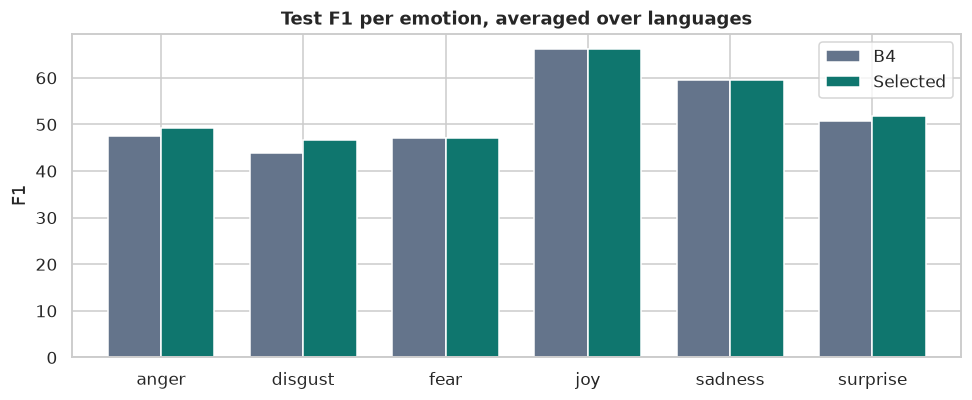

|  | B4 | Selected |
|---|---|---|
| anger | 47.48 | 49.17 |
| disgust | 43.91 | 46.61 |
| fear | 47.14 | 47.13 |
| joy | 66.10 | 66.13 |
| sadness | 59.52 | 59.52 |
| surprise | 50.74 | 51.88 |

In [39]:
by_emotion = pd.DataFrame({k: E.per_emotion_f1(v["y"], v["pred"], v["mask"], v["lang"]) for k, v in test.items()}) * 100

ax = by_emotion.plot.bar(figsize=(9, 3.8), color=[SLATE, TEAL], rot=0, width=0.75)
ax.set(title="Test F1 per emotion, averaged over languages", ylabel="F1", xlabel="")
plt.show()
by_emotion.round(2)

**Interpretation.** Joy and sadness are the easiest emotions in both models, and disgust and fear are among the hardest. The selected model improves disgust (+2.70), anger (+1.69) and surprise (+1.14), and matches B4 on fear, joy and sadness.

### 7.3 Statistical comparison and quality measures

In [40]:
a, b = test["Selected"], test["B4"]
boot = E.paired_bootstrap(a["y"], a["pred"], b["pred"], a["mask"], a["lang"])
quality = pd.DataFrame({k: {"Co-occurrence fidelity (lower is better)": E.cooccurrence_fidelity(v["y"], v["pred"], v["mask"], v["lang"]),
                            "Calibration error, ECE (lower is better)": E.ece(v["p"][:, :6], v["y"], v["mask"])} for k, v in test.items()})

display(Markdown(f'''
**Paired bootstrap, 1,000 resamples, Selected minus B4**

- Difference: **{boot['mean_diff'] * 100:+.2f}** points
- 95% interval: {boot['ci_low'] * 100:.2f} to {boot['ci_high'] * 100:.2f}
- One-sided p-value: {boot['p_value']:.3f}

The bootstrap resamples test rows only. It does not capture variation between seeds, and each model here has one seed.
'''))
quality.round(4)


**Paired bootstrap, 1,000 resamples, Selected minus B4**

- Difference: **+0.92** points
- 95% interval: 0.46 to 1.39
- One-sided p-value: 0.000

The bootstrap resamples test rows only. It does not capture variation between seeds, and each model here has one seed.


|  | B4 | Selected |
|---|---|---|
| Co-occurrence fidelity (lower is better) | 0.403 | 0.335 |
| Calibration error, ECE (lower is better) | 0.125 | 0.12 |

**Interpretation.**

- **Bootstrap:** the test rows were resampled 1,000 times. A p-value of 0.000 means none of those resamples favoured B4, so p is below 0.001. The whole 95% interval is above zero, so the gain is unlikely to be due to which test rows were drawn. It is still a small gain from a single trained model of each kind.
- **Co-occurrence fidelity** measures how closely predicted emotion pairs match the real ones. The selected model is better, at 0.335 against 0.403.
- **Calibration error (ECE)** measures whether a predicted probability of, say, 70% is right about 70% of the time. The two models are close, at 0.120 and 0.125.

### 7.4 Track B: intensity

Only the selected model predicts intensity, so B4 has no Track B score.

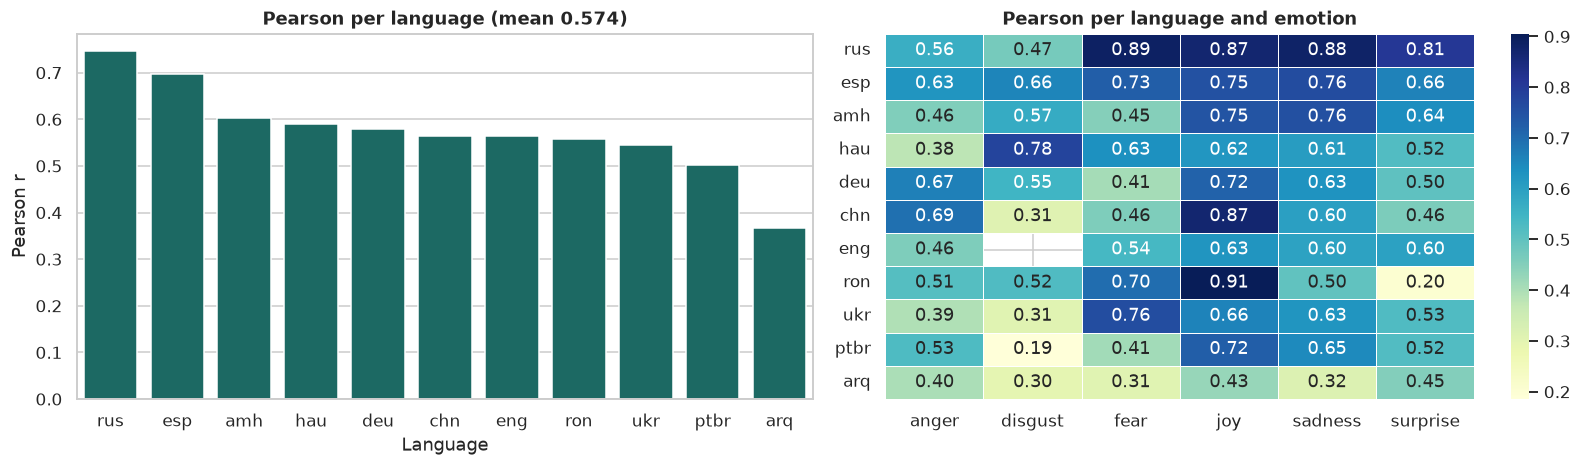

In [41]:
track_b = E.track_b(a["intensity"], a["int_pred"], a["lang"])
pearson = pd.Series(track_b["per_language"]).sort_values(ascending=False)
detail = pd.DataFrame(track_b["per_emotion"]).T.reindex(pearson.index)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
sns.barplot(x=pearson.index, y=pearson.values, color=TEAL, ax=axes[0])
axes[0].set(title=f"Pearson per language (mean {track_b['mean']:.3f})", ylabel="Pearson r", xlabel="Language")
sns.heatmap(detail, annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[1], linewidths=0.4)
axes[1].set(title="Pearson per language and emotion", xlabel="", ylabel="")
plt.show()

**Interpretation.** The left chart gives the mean Pearson correlation per language, and the right chart breaks it down by emotion. A value of 1 would be a perfect match. The overall mean of 0.574 is moderate: clearly above chance, but with real error.

Russian (0.746) and Spanish (0.698) are strongest, and Algerian Arabic (0.367) is weakest. Joy has the highest correlation on average, and results vary widely by emotion and language: disgust, for example, runs from 0.78 in Hausa to 0.19 in Brazilian Portuguese. The blank cell is English disgust, which does not exist. No separate intensity baseline was run, so these values cannot be compared with a simpler method.

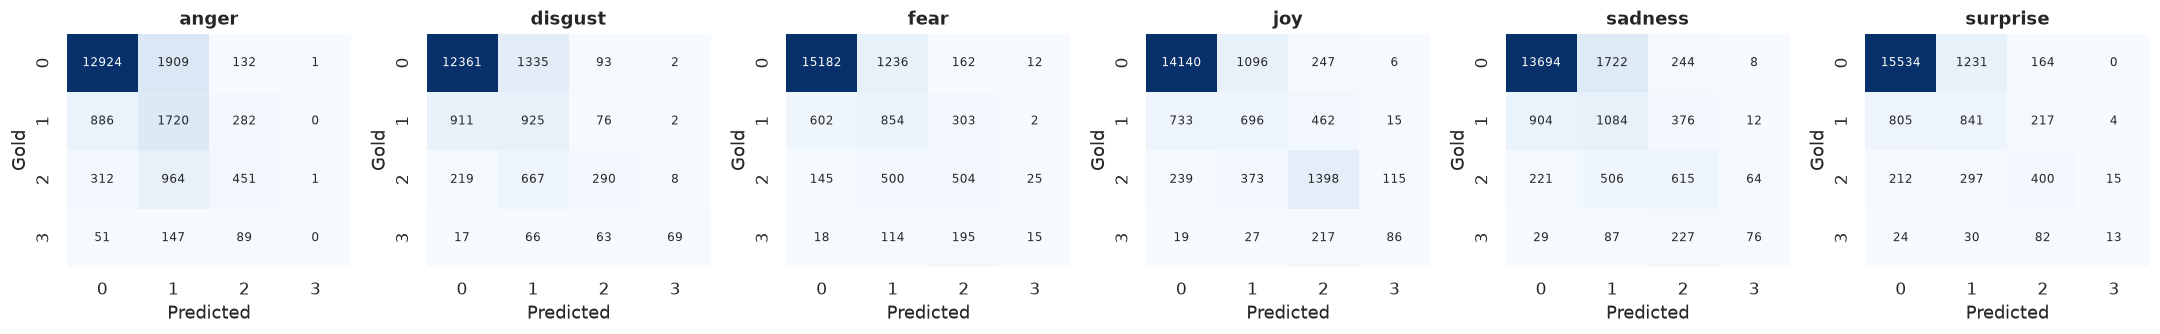

In [42]:
confusion = E.intensity_confusion(a["intensity"], a["int_pred"])
shown = [e for e in EMOS if np.sum(confusion[e])]
fig, axes = plt.subplots(1, len(shown), figsize=(3.3 * len(shown), 3.2))
for ax, emotion in zip(np.atleast_1d(axes), shown):
    sns.heatmap(np.array(confusion[emotion]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 8})
    ax.set(title=emotion, xlabel="Predicted", ylabel="Gold")
plt.show()

**Interpretation.** Mass on and near the diagonal means predicted levels sit close to the gold level. Rows are gold levels 0 to 3, and columns are predicted levels. The dark top-left cell in each matrix shows that "no emotion" (level 0) is recognised well. High intensities are harder: across all emotions, only 259 of the 1,761 true level-3 cases are predicted as 3, and most land on level 2. Anger is the extreme case, with none of its 287 level-3 cases predicted as 3. Most errors are one level off, which is what the distance-aware loss is meant to encourage.

### 7.5 Track C: languages never trained on

Indonesian, Javanese, Xhosa and Zulu have no training rows. The model reaches them through its encoder, its family or global graph, and the pooled thresholds.

In [43]:
track_c = E.load_preds(cfg, run_best, "trackc")
if track_c is None:
    print("No Track C predictions found.")
else:
    c_scores = E.score_track_a(track_c)
    c_table = (pd.Series(c_scores["per_language"]) * 100).round(2).to_frame("Macro-F1")
    c_table.loc["mean"] = round(c_scores["mean"] * 100, 2)
    display(c_table)

|  | Macro-F1 |
|---|---|
| ind | 45.78 |
| jav | 29.24 |
| xho | 3.45 |
| zul | 5.11 |
| mean | 20.90 |

**Interpretation.** The model never trained on these four languages. Indonesian (45.78) and Javanese (29.24) reach usable scores, while Xhosa (3.45) and Zulu (5.11) are close to zero, which brings the mean down to 20.90. Zero-shot transfer works only for languages reasonably close to the training data.

### 7.6 Comparison with the original runs

Earlier full-data runs are recorded in the project reports. The table below sets this notebook's scores beside them. When saved weights were re-scored, the numbers should match. When a model was retrained, small differences are expected.

In [44]:
report = ROOT / "reports/results_best.md"
recorded = {}
if report.exists():
    for line in report.read_text(encoding="utf-8").splitlines():
        if line.startswith("| Test, all 28"):
            cells = [c.strip() for c in line.strip("|").split("|")]
            recorded = {"B4": float(cells[1]), "Selected": float(cells[4])}

if recorded:
    repeat = pd.DataFrame({"Original run": recorded, "This notebook": per_language[["B4", "Selected"]].mean()})
    repeat["Difference"] = repeat["This notebook"] - repeat["Original run"]
    display(repeat.round(2))
else:
    print("Original report not found.")

|  | Original run | This notebook | Difference |
|---|---|---|---|
| B4 | 52.54 | 52.54 | 0.00 |
| Selected | 53.47 | 53.47 | -0.00 |

**Interpretation.** The difference is zero because this run re-scored the original saved weights, so it reproduces the reported results exactly. A value of $-0.00$ is only a rounding artefact. If the models are retrained, small differences are expected, because GPU training is not perfectly repeatable.

## 8. Conclusions

In [45]:
s_mean, b_mean = per_language["Selected"].mean(), per_language["B4"].mean()
b1_line = f"- Both neural models compare with a TF-IDF baseline at {per_language['B1'].mean():.2f}.\n" if "B1" in per_language else ""
c_line = f"- Track C, on languages never trained on, reaches {c_scores['mean'] * 100:.2f}.\n" if track_c is not None else ""
display(Markdown(f'''
**Results from this run**

- **Track A:** the selected model scores {s_mean:.2f}, and B4 scores {b_mean:.2f}, across {len(per_language)} languages.
{b1_line}- **Track B:** the selected model reaches a mean Pearson of {track_b['mean']:.3f} on {len(pearson)} languages.
{c_line}- The selected model beats B4 on {(gap > 0).sum()} of {len(gap)} languages.
- The gap between the best and worst language is {per_language['Selected'].max() - per_language['Selected'].min():.1f} points, so language matters far more than model choice.
'''))


**Results from this run**

- **Track A:** the selected model scores 53.47, and B4 scores 52.54, across 28 languages.
- Both neural models compare with a TF-IDF baseline at 39.76.
- **Track B:** the selected model reaches a mean Pearson of 0.574 on 11 languages.
- Track C, on languages never trained on, reaches 20.90.
- The selected model beats B4 on 18 of 28 languages.
- The gap between the best and worst language is 59.4 points, so language matters far more than model choice.


**What this shows**

- In the original runs, the intensity head added a second output to LDGN without a loss in emotion detection. Section 7.6 compares this run with them.
- Language remains the main source of variation. The weakest languages stay weak under both models.
- The data analysis explains some of the behaviour seen later. The English fear skew, in particular, carries over to the applications.

**Limitations**

- Each model here has one seed, so small differences should be read with care.
- Local scores use the same metrics as the official scorer, but they are not leaderboard results.
- Test scores from earlier runs were already known, so these are repeat runs and not a blind evaluation.
- Reference models with all five additions, and the subset experiments behind the selection, are in the project report.

**Next steps**

- Add seeds on full data to measure how stable the gain is.
- Test the signed graph (N2) together with the intensity head.
- Evaluate on the weakest languages directly, with more data or an encoder suited to them.